# Decision Tree Regressor — Thermal Predictor

Modelo de árvore de decisão multi-output que prevê a temperatura de cada termopar
(`tc_name`) de uma `key_area` a partir das sete variáveis de configuração do ensaio.

**Um modelo por setor:** cada `key_area` recebe sua própria árvore, treinada apenas
com os runs e os termopares daquela região. Isso é coerente com a H1 documentada na
Seção 4.2.3 — o efeito de uma configuração muda de sinal conforme a área, então um
modelo único para todas as regiões estimaria um efeito médio que não descreve
nenhuma delas.

**Entrada:** planilhas em formato wide geradas por `tratamento_final_dos_dados.ipynb`
(`data/<key_area>_data.csv`) — uma linha por run, uma coluna por termopar.

As sete planilhas têm o mesmo formato (na versão atual da base, 19 linhas cada) e
diferem no número de termopares (4 a 22) e em quais sensores foram medidos em quais
runs. O pipeline é escrito em funções que se adaptam ao arquivo carregado, sem nenhum
parâmetro fixo por área.

**Estrutura do notebook:**

| Seções | Conteúdo |
|---|---|
| 1 a 7 | **Uma** área em detalhe (altere `CAMINHO_PLANILHA` na Célula 2 para trocar de área): leitura, codificação, divisão, treino, regras da árvore e métricas por termopar |
| 8 a 10 | As **sete** áreas de uma vez: treino por setor, comparativo e comparação com o baseline "média do termopar" (semente 42) |
| 11 e 12 | **O resultado depende do split?** Sensibilidade à semente e árvore vs. baseline em 31 sementes — é a base para dizer em quais áreas a árvore realmente agrega informação |
| 13 a 16 | **Tuning e overfitting:** antes vs. depois do tuning, gráficos, interpretação e os experimentos que justificam as escolhas da Célula 5 |
| 17 | **LOGO:** validação Leave-One-Group-Out por setor e comparação entre estimadores (média, mediana, híbrido e baseline) |

Este notebook é o par do `Random_for_regre.ipynb`: mesma preparação de dados e mesma
avaliação, trocando o Random Forest pela árvore única. A diferença que interessa ao
parceiro é a explicabilidade — uma árvore pode ser lida como regra de decisão
(Célula 6), o que uma floresta de 300 árvores não permite.

## 1. Bibliotecas e configuração global

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedKFold
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
# Semente global: controla a divisão treino/teste/verificação e o desempate entre
# splits equivalentes da árvore. Altere aqui para reexecutar o notebook inteiro
# com outra semente; a Seção 11 compara várias sementes sem mexer neste valor.
# Random Forest e Gradient Boosting também usam 42 — mantenha os três iguais para
# que avaliem as mesmas linhas (comparação final entre os três modelos).
SEMENTE = 42

## 2. Parâmetros e leitura da planilha

Formato wide: cada termopar é uma coluna-alvo independente. Tudo que não está em
`VARIAVEIS_INDEPENDENTES` é candidato a alvo.

Duas checagens são feitas na leitura, porque nem toda coluna extra é um termopar
válido: colunas **sem nome** (`Unnamed: N`, geradas quando o `tc_name` original
estava em branco — é o caso de `ct_knobs_data.csv`) e colunas **inteiramente
vazias** são descartadas com aviso, em vez de entrarem como alvo do modelo.

In [2]:
# ============================================================
# CÉLULA 2 — PARÂMETROS E LEITURA DA PLANILHA
# Formato wide: cada termopar é uma coluna-alvo independente
# ============================================================

# Troque aqui para analisar outra key_area em detalhe:
#   ../data/mainback_data.csv        ../data/ipc_comp_data.csv
#   ../data/coil_temps_data.csv      ../data/ipc_cooling_data.csv
#   ../data/main_vent_sys_data.csv   ../data/oven_hmi_data.csv
#   ../data/ct_knobs_data.csv
CAMINHO_PLANILHA = "../data/mainback_data.csv"

VARIAVEIS_INDEPENDENTES = [
    "blower_direction",
    "housing",
    "board_position",
    "run_case",
    "losses",
    "deflector_hole",
    "material_coil_support",
]

# Um termopar só entra como alvo se tiver leitura em pelo menos esta fração dos
# runs. Sensores abaixo disso são removidos como COLUNA — descartá-los custa um
# alvo, enquanto exigir que estejam presentes custaria quase todos os runs.
COBERTURA_MINIMA_ALVO = 0.50

# Número de folds do GridSearchCV. É reduzido automaticamente se o conjunto de
# treino for pequeno demais (ver Célula 5).
N_FOLDS_DESEJADO = 3


def identificar_alvos(df, independentes):
    """Separa as colunas-alvo válidas das colunas que não representam termopar."""
    alvos, descartadas = [], []
    for coluna in df.columns:
        if coluna in independentes:
            continue
        if str(coluna).startswith("Unnamed:") or not str(coluna).strip():
            descartadas.append((coluna, "coluna sem nome de termopar"))
        elif df[coluna].isna().all():
            descartadas.append((coluna, "coluna inteiramente vazia"))
        else:
            alvos.append(coluna)
    return alvos, descartadas


def resumir_alvos(df, alvos):
    """Tabela de cobertura e estatística descritiva de cada termopar."""
    return pd.DataFrame([
        {
            "termopar": alvo,
            "leituras": int(df[alvo].notna().sum()),
            "cobertura": df[alvo].notna().mean(),
            "min": df[alvo].min(),
            "max": df[alvo].max(),
            "média": df[alvo].mean(),
            "desvio": df[alvo].std(),
        }
        for alvo in alvos
    ]).sort_values("cobertura", ascending=False, ignore_index=True)


def listar_alvos_duplicados(df, alvos):
    """Pares de termopares com leitura idêntica (possível duplicação de sensor)."""
    return [
        (alvo_a, alvo_b)
        for i, alvo_a in enumerate(alvos)
        for alvo_b in alvos[i + 1:]
        if df[alvo_a].equals(df[alvo_b])
    ]


dados = pd.read_csv(CAMINHO_PLANILHA)
VARIAVEIS_ALVO, COLUNAS_DESCARTADAS = identificar_alvos(dados, VARIAVEIS_INDEPENDENTES)

print(f"Arquivo: {CAMINHO_PLANILHA}")
print(f"Linhas: {len(dados)} | Colunas: {dados.shape[1]}")

if COLUNAS_DESCARTADAS:
    print("\nColunas ignoradas (não são termopares válidos):")
    for coluna, motivo in COLUNAS_DESCARTADAS:
        print(f"   {coluna!r}: {motivo}")

print(f"\nTermopares candidatos ({len(VARIAVEIS_ALVO)}):")
print(resumir_alvos(dados, VARIAVEIS_ALVO).round(2).to_string(index=False))

print(f"\nValores nulos nos alvos: {int(dados[VARIAVEIS_ALVO].isna().sum().sum())}")

duplicadas = listar_alvos_duplicados(dados, VARIAVEIS_ALVO)
if duplicadas:
    print("\nATENÇÃO — colunas-alvo com valores idênticos:")
    for alvo_a, alvo_b in duplicadas:
        print(f"   {alvo_a}  ==  {alvo_b}")

dados.head()

Arquivo: ../data/mainback_data.csv
Linhas: 19 | Colunas: 17

Termopares candidatos (10):
                          termopar  leituras  cobertura   min    max  média  desvio
       ACU Ambient (Hill Only) Top        19        1.0 52.96  90.86  59.47   10.17
ACU K8 Housing / Double Line Break        19        1.0 44.93  68.08  48.85    6.71
      Ambient Below Terminal Block        19        1.0 41.66  73.91  46.28    8.17
             Convect Motor Winding        19        1.0 77.83 103.87  83.88    7.16
        Door Lock Microswitch Body        19        1.0 88.14 105.68  95.79    4.95
Door Lock Motor Ambient 1/2" Below        19        1.0 82.11 101.10  92.47    4.12
        Hot Surface Indicator Body        19        1.0 39.22  51.41  42.98    3.00
              L2, Wire, Power Cord        19        1.0 45.04  77.33  50.19    8.71
           Power On Indicator Body        19        1.0 40.44  47.86  43.71    1.67
      Storage Drawer (Metal Above)        19        1.0 95.26 140.91 10

,blower_direction,housing,board_position,run_case,losses,deflector_hole,material_coil_support,ACU Ambient (Hill Only) Top,ACU K8 Housing / Double Line Break,Ambient Below Terminal Block,Convect Motor Winding,Door Lock Microswitch Body,"Door Lock Motor Ambient 1/2"" Below",Hot Surface Indicator Body,"L2, Wire, Power Cord",Power On Indicator Body,Storage Drawer (Metal Above)
0,To back,Closed,Center,Broil C2,Correct Level,Simone Modified - Back Order,Closed,64.03,48.760,46.650,87.910,105.680,98.050,44.290,50.570,42.570,100.540
1,To back,Open,Center,Broil C2,Correct Level,Simone Modified - Back Order,Closed,83.34,66.390,62.850,100.590,94.725,84.870,47.970,70.900,44.510,100.100
2,To back,Open,Center,Broil Qualitative,Correct Level,Não informado,Open,90.86,68.080,73.910,103.870,88.250,82.110,43.420,77.330,40.440,96.720
3,To front,Closed,Center,Broil,Correct Level,Miro,Closed,55.78,46.335,44.005,81.485,88.135,92.665,39.595,46.665,44.035,95.375
4,To front,Closed,Center,Broil,Correct Level,Simone,Closed,57.16,46.800,44.890,83.085,94.110,92.145,41.975,48.150,43.755,95.255


## 3. Seleção de alvos, padronização das categorias e codificação

Primeiro descarta o **sensor** de cobertura baixa (coluna), depois descarta as
**linhas** que ainda tenham buraco entre os alvos que sobraram. A ordem importa:
fazer `dropna` direto sobre todos os alvos é *listwise deletion* — basta um sensor
pouco medido para eliminar quase todos os runs. Em `main_vent_sys_data.csv`, dois
sensores medidos em apenas 4 dos 56 runs derrubariam a base de 56 para 4 linhas.

A codificação é **one-hot**: cada categoria vira uma coluna 0/1 (`variável=categoria`).
A codificação ordinal anterior numerava as categorias em ordem alfabética, e a árvore
cortava `variável <= k` como se houvesse uma ordem — para `deflector_hole`, com 13
categorias em ~19 linhas, isso agrupava categorias sem relação entre si. Medido em 30
sementes x 7 setores, o one-hot reduziu o MAE fora do treino de 5,94 para 5,45 °C
(-8%; Wilcoxon p = 0,028, sem correção para múltiplas comparações). Ele melhora a
generalização; o overfitting em si é contido pela grade restrita da Célula 5.
As colunas geradas dependem das categorias presentes em cada setor.


In [3]:
# ============================================================
# CÉLULA 3 — SELEÇÃO DE ALVOS, PADRONIZAÇÃO E CODIFICAÇÃO ORDINAL
# ============================================================
GRAFIAS_DIVERGENTES = {
    "blower_direction": {"To back": "To Back", "To front": "To Front"},
    "losses":           {"No losses": "No Losses"},
    "run_case":         {"Broil Case 2": "Broil C2", "Broil Qual": "Broil Qualitative", "Qualitative": "Broil Qualitative"},
    "housing":          {"Open - Updated": "Open"}
}


def filtrar_alvos_por_cobertura(df, alvos, cobertura_minima):
    """Mantém apenas os termopares medidos em uma fração mínima dos runs."""
    mantidos, removidos = [], []
    for alvo in alvos:
        cobertura = df[alvo].notna().mean()
        if cobertura >= cobertura_minima:
            mantidos.append(alvo)
        else:
            removidos.append((alvo, int(df[alvo].notna().sum()), cobertura))
    return mantidos, removidos


def padronizar_categorias(df, independentes, correcoes_por_variavel):
    """Unifica grafias divergentes e transforma nulos em categoria explícita."""
    df = df.copy()
    for variavel, correcoes in correcoes_por_variavel.items():
        if variavel in df.columns:
            df[variavel] = df[variavel].replace(correcoes)
    for variavel in independentes:
        df[variavel] = df[variavel].fillna("Nao Informado").astype(str)
    return df


def codificar_one_hot(df, independentes):
    """One-hot: uma coluna 0/1 por categoria ("variável=categoria").

    Evita a ordem alfabética inventada da codificação ordinal, que fazia a árvore
    cortar `deflector_hole <= 6` agrupando categorias sem relação entre si. Em 30
    sementes x 7 setores, o one-hot reduziu o MAE fora do treino de 5,94 para
    5,45 °C (-8%). Devolve X e um dicionário {variável: [colunas geradas]} — a lista
    de colunas é o esquema que qualquer previsão futura precisa reproduzir.
    """
    X = pd.get_dummies(df[independentes], prefix_sep="=", dtype=float)
    dicionario = {
        variavel: [coluna for coluna in X.columns if coluna.startswith(f"{variavel}=")]
        for variavel in independentes
    }
    return X, dicionario


# 1) Descarta o SENSOR pouco medido (coluna), não o run (linha).
VARIAVEIS_ALVO, alvos_removidos = filtrar_alvos_por_cobertura(
    dados, VARIAVEIS_ALVO, COBERTURA_MINIMA_ALVO
)

if alvos_removidos:
    print(f"Termopares removidos por cobertura < {COBERTURA_MINIMA_ALVO:.0%}:")
    for alvo, leituras, cobertura in alvos_removidos:
        print(f"   {alvo:40s} {leituras:3d}/{len(dados)} runs ({cobertura:.1%})")
    print()

if not VARIAVEIS_ALVO:
    raise ValueError(
        f"Nenhum termopar atingiu a cobertura mínima de {COBERTURA_MINIMA_ALVO:.0%}. "
        f"Reduza COBERTURA_MINIMA_ALVO na Célula 2 para modelar este arquivo."
    )

# 2) Só agora descarta as LINHAS com buraco entre os alvos que sobraram.
dados_tratados = dados.dropna(subset=VARIAVEIS_ALVO).copy()

linhas_removidas = len(dados) - len(dados_tratados)
if linhas_removidas:
    print(f"Linhas removidas por alvo ausente: {linhas_removidas}\n")

dados_tratados = padronizar_categorias(
    dados_tratados, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES
)
X, dicionario_codificacao = codificar_one_hot(dados_tratados, VARIAVEIS_INDEPENDENTES)
Y = dados_tratados[VARIAVEIS_ALVO]

print("Colunas geradas pelo one-hot:\n")
for variavel, colunas in dicionario_codificacao.items():
    print(f"{variavel} ({len(colunas)} colunas)")
    for coluna in colunas:
        print(f"   {coluna}")
    print()

print(f"Matriz de features: {X.shape}")
print(f"Colunas-alvo: {len(VARIAVEIS_ALVO)}")
print(f"Linhas úteis: {len(dados_tratados)} de {len(dados)}")
print(f"Combinações distintas de configuração: {X.drop_duplicates().shape[0]}")

Colunas geradas pelo one-hot:

blower_direction (2 colunas)
   blower_direction=To Back
   blower_direction=To Front

housing (2 colunas)
   housing=Closed
   housing=Open

board_position (1 colunas)
   board_position=Center

run_case (5 colunas)
   run_case=Broil
   run_case=Broil C1
   run_case=Broil C2
   run_case=Broil Qualitative
   run_case=Pyro

losses (1 colunas)
   losses=Correct Level

deflector_hole (13 colunas)
   deflector_hole=Broil C2 Simone - 240/145/180/180
   deflector_hole=Broil C2 Simone - Front Order
   deflector_hole=Broil Miro - Front Order
   deflector_hole=C1 Simone - 240/145/180/180
   deflector_hole=Miro
   deflector_hole=Miro - Front Order
   deflector_hole=Miro Qualitative  - Back Order
   deflector_hole=Miro Qualitative  - Front Order
   deflector_hole=No losses
   deflector_hole=Não informado
   deflector_hole=Qual Simone - Front Order
   deflector_hole=Simone
   deflector_hole=Simone Modified - Back Order

material_coil_support (2 colunas)
   material_co

## 4. Separação treino (70%) / teste (20%) / verificação (10%)

`Y` é matricial: uma coluna por termopar, lida de `dados_tratados` para permanecer
alinhada com as linhas de `X`.

A célula checa antes da divisão se sobraram linhas suficientes para formar os três
conjuntos e ainda alimentar a validação cruzada, falhando com uma mensagem que diz
o que ajustar — em vez do `ValueError` genérico do `GridSearchCV`.

In [4]:
# ============================================================
# CÉLULA 4 — SEPARAÇÃO TREINO (70%) / TESTE (20%) / VERIFICAÇÃO (10%)
# Y é matricial (uma coluna por termopar)
# ============================================================
PROPORCAO_TREINO = 0.70
PROPORCAO_TESTE = 0.20
PROPORCAO_VERIFICACAO = 0.10

MINIMO_DE_LINHAS = 10
if len(X) < MINIMO_DE_LINHAS:
    raise ValueError(
        f"Apenas {len(X)} linhas úteis após o tratamento — insuficiente para dividir em "
        f"treino/teste/verificação e rodar validação cruzada. Verifique a Célula 3: "
        f"provavelmente há termopares esparsos derrubando linhas. Considere reduzir "
        f"COBERTURA_MINIMA_ALVO (hoje {COBERTURA_MINIMA_ALVO:.0%}) na Célula 2."
    )

X_treino, X_restante, Y_treino, Y_restante = train_test_split(
    X, Y,
    train_size=PROPORCAO_TREINO,
    random_state=SEMENTE,
)

proporcao_verificacao_no_restante = (
    PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO)
)

X_teste, X_verificacao, Y_teste, Y_verificacao = train_test_split(
    X_restante, Y_restante,
    test_size=proporcao_verificacao_no_restante,
    random_state=SEMENTE,
)

print(f"Treino:       {len(X_treino):3d} linhas ({len(X_treino)/len(X):.1%})")
print(f"Teste:        {len(X_teste):3d} linhas ({len(X_teste)/len(X):.1%})")
print(f"Verificação:  {len(X_verificacao):3d} linhas ({len(X_verificacao)/len(X):.1%})")
print(f"\nFormato de X: {X_treino.shape}  |  Formato de Y: {Y_treino.shape}")

Treino:        13 linhas (68.4%)
Teste:          4 linhas (21.1%)
Verificação:    2 linhas (10.5%)

Formato de X: (13, 26)  |  Formato de Y: (13, 10)


## 5. Treinamento do modelo (Decision Tree multi-output)

`DecisionTreeRegressor` também suporta múltiplas saídas nativamente: cada folha
armazena um vetor de médias, uma por termopar.

A grade de hiperparâmetros é toda de **controle de complexidade** — `max_depth` (1 a 3),
`min_samples_leaf` (>= 2) e `min_samples_split`. Em uma árvore única isso
pesa mais do que no Random Forest: sem a média sobre muitas árvores, uma árvore
profunda decora o treino. Com ~40 linhas de treino, deixar `max_depth=None` produz
folhas de uma amostra só.

A validação cruzada é **repetida** (`RepeatedKFold`, 5 repetições): com ~13 linhas de
treino, 3 folds simples têm ~4 linhas e a escolha de hiperparâmetros vira sorteio. O
número de folds continua `min(N_FOLDS_DESEJADO, linhas de treino)`, com mínimo de 2.

**Por que esta grade:** em 30 sementes × 7 setores, a grade anterior (`max_depth` até 8,
folhas de 1 linha) tinha gap médio treino→teste de +3,5 °C; esta reduz para ~+2,1 °C
(-41%). Mesmo assim o gap não chega a zero — com 19 linhas por setor, parte dele é
variância irredutível do conjunto de teste, não superajuste.

**Regra do 1 erro-padrão:** entre as combinações da grade, a árvore final não é a de
menor erro na validação cruzada, e sim a **mais simples** cujo erro está a até 1
erro-padrão da melhor (menor `max_depth`, depois maior `min_samples_leaf`). Com ~13
linhas, o mínimo da validação cruzada costuma premiar sorte; a regra reduziu o gap
treino→fora do treino em 22% (+1,82 para +1,41 °C, p < 0,001) e o erro em linhas não
vistas em 3% (Seção 16).

Hiperparâmetros escolhidos (regra do 1 erro-padrão):
   max_depth: 1
   min_samples_leaf: 4
   min_samples_split: 8

Saídas do modelo: 10 termopares
Profundidade da árvore: 1 | Folhas: 2

Importância das variáveis:
run_case                 1.0
board_position           0.0
blower_direction         0.0
deflector_hole           0.0
housing                  0.0
losses                   0.0
material_coil_support    0.0


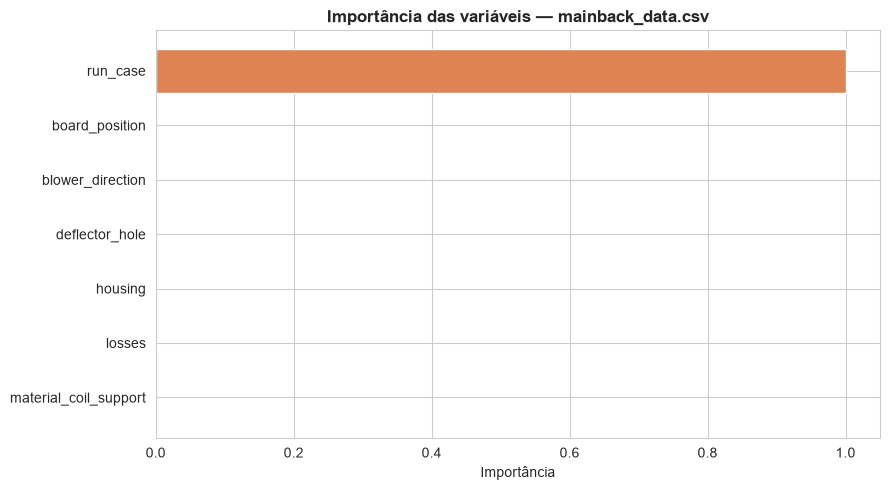

In [5]:
# ============================================================
# CÉLULA 5 — TREINAMENTO DO MODELO (DECISION TREE MULTI-OUTPUT)
# DecisionTreeRegressor suporta múltiplas saídas nativamente:
# cada folha armazena um vetor de médias, uma por termopar.
# ============================================================
# Grade desenhada para CONTER o superajuste com ~13 linhas de treino por setor:
#  - max_depth <= 3 e min_samples_leaf >= 2: impede folhas de uma única linha
#    (a grade anterior deixava chegar a max_depth=8 com 13 folhas para 13 linhas);
#  - max_features removido: sortear 2-3 de 7 variáveis é ruído numa árvore única;
#  - ccp_alpha (poda) NÃO entra: seu efeito depende da escala da temperatura de cada
#    setor e, em teste, podava a árvore até uma folha única (= prever a média).
GRADE_HIPERPARAMETROS = {
    "max_depth":         [1, 2, 3],
    "min_samples_leaf":  [2, 3, 4],
    "min_samples_split": [4, 6, 8],
}

N_REPETICOES_CV = 5


def validacao_cruzada(n_linhas_treino, semente):
    """K-fold REPETIDO: com ~13 linhas, 3 folds simples dão folds de ~4 linhas e uma
    escolha de hiperparâmetros dominada pelo sorteio. Repetir com embaralhamentos
    diferentes estabiliza a escolha sem gastar linhas extras."""
    n_splits = max(2, min(N_FOLDS_DESEJADO, n_linhas_treino))
    return RepeatedKFold(n_splits=n_splits, n_repeats=N_REPETICOES_CV, random_state=semente)


def buscar_arvore(X_tr, Y_tr, semente):
    """Busca de hiperparâmetros com a regra do 1 erro-padrão.

    Em vez de ficar com a combinação de menor erro na validação cruzada (que, com ~13
    linhas, muitas vezes premia sorte), escolhe a combinação MAIS SIMPLES cujo erro
    está a até 1 erro-padrão da melhor: menor `max_depth`, depois maior
    `min_samples_leaf`, depois maior `min_samples_split`.
    Devolve (árvore treinada, hiperparâmetros escolhidos, GridSearchCV).
    """
    cv = validacao_cruzada(len(X_tr), semente)
    busca = GridSearchCV(
        estimator=DecisionTreeRegressor(random_state=semente),
        param_grid=GRADE_HIPERPARAMETROS,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1,          # árvores minúsculas: o custo de paralelizar supera o ganho
    ).fit(X_tr, Y_tr)

    resultados_cv = pd.DataFrame(busca.cv_results_)
    melhor = resultados_cv[resultados_cv["rank_test_score"] == 1].iloc[0]
    erro_padrao = melhor["std_test_score"] / np.sqrt(cv.get_n_splits())
    aceitaveis = resultados_cv[
        resultados_cv["mean_test_score"] >= melhor["mean_test_score"] - erro_padrao
    ]
    escolhidos = aceitaveis.sort_values(
        ["param_max_depth", "param_min_samples_leaf", "param_min_samples_split"],
        ascending=[True, False, False],
    ).iloc[0]["params"]

    arvore = DecisionTreeRegressor(random_state=semente, **escolhidos).fit(X_tr, Y_tr)
    return arvore, escolhidos, busca


modelo, melhores_parametros, busca = buscar_arvore(X_treino, Y_treino, SEMENTE)

print("Hiperparâmetros escolhidos (regra do 1 erro-padrão):")
for parametro, valor in melhores_parametros.items():
    print(f"   {parametro}: {valor}")

print(f"\nSaídas do modelo: {modelo.n_outputs_} termopares")
print(f"Profundidade da árvore: {modelo.get_depth()} | Folhas: {modelo.get_n_leaves()}")

# A importância é única para o modelo — reflete todos os alvos em conjunto
# Com one-hot há uma coluna por categoria; somar por variável de origem mantém a leitura.
importancia = (
    pd.Series(modelo.feature_importances_, index=X_treino.columns)
      .groupby(lambda coluna: coluna.split("=")[0]).sum()
      .sort_values(ascending=False)
)
print(f"\nImportância das variáveis:\n{importancia.round(4).to_string()}")

plt.figure(figsize=(9, 5))
plt.barh(importancia.index[::-1], importancia.values[::-1], color="#DD8452")
plt.xlabel("Importância")
plt.title(f"Importância das variáveis — {CAMINHO_PLANILHA.split('/')[-1]}",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(f"../assets/graficos/dt_importancia_{CAMINHO_PLANILHA.split('/')[-1].replace('_data.csv', '')}.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Leitura da árvore — regras de decisão

A vantagem da árvore única sobre o Random Forest é poder ser lida diretamente: cada
caminho da raiz até uma folha é uma regra do tipo "se `housing=Open` for 1 e
`run_case=Pyro` for 0, então a temperatura prevista é X".

O desenho e o texto são cortados em `PROFUNDIDADE_EXIBIDA` níveis para permanecerem
legíveis — a árvore treinada pode ser mais profunda que isso.

**Ressalva importante, alinhada à H2 (Seção 4.2.3):** as sete configurações estão
confundidas no desenho dos ensaios — `losses` é redundante com `deflector_hole`, e
das 36 combinações possíveis entre as três variáveis principais apenas 11 foram
ensaiadas. A árvore escolhe uma entre variáveis redundantes de forma arbitrária.
Estas regras descrevem **blocos de configuração** presentes na base, não a
contribuição causal de uma peça isolada, e não devem ser apresentadas ao parceiro
como evidência de causa.

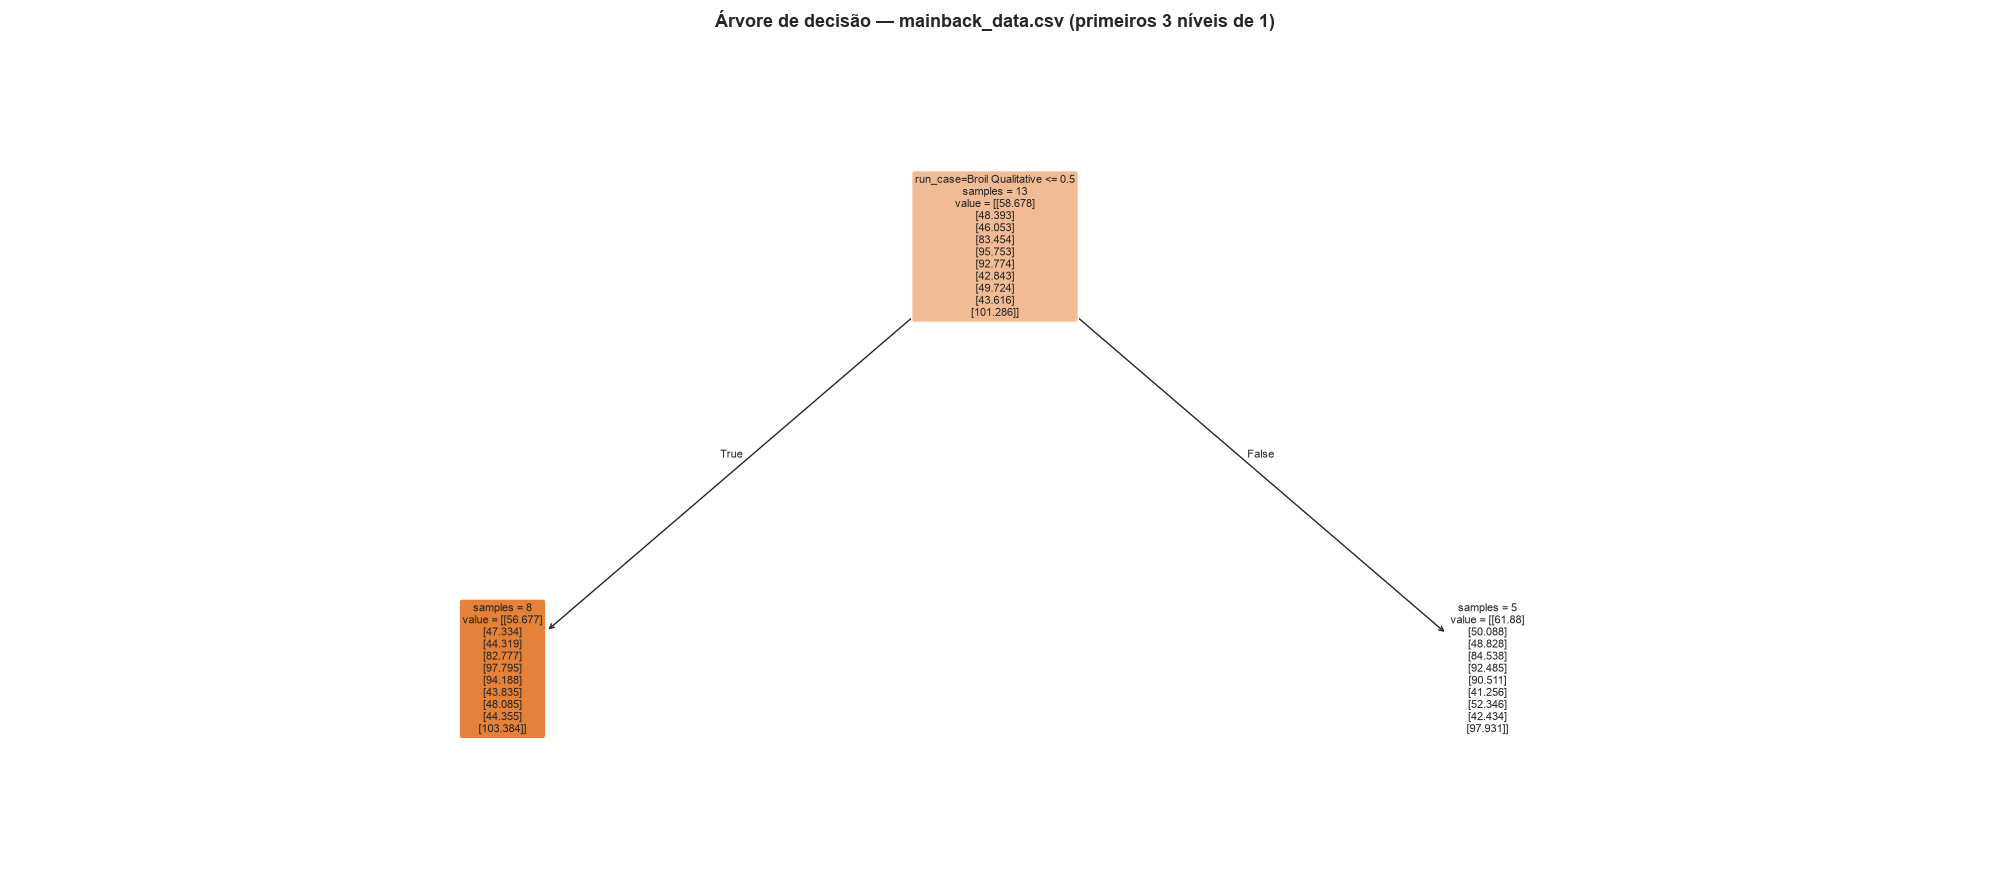

Regras até o nível 3:

|--- run_case=Broil Qualitative <= 0.5
|   |--- value: [56.7, 47.3, 44.3, 82.8, 97.8, 94.2, 43.8, 48.1, 44.4, 103.4]
|--- run_case=Broil Qualitative >  0.5
|   |--- value: [61.9, 50.1, 48.8, 84.5, 92.5, 90.5, 41.3, 52.3, 42.4, 97.9]

Colunas one-hot das variáveis mais importantes (corte `coluna <= 0.5` = "não é essa categoria"):

   run_case: run_case=Broil, run_case=Broil C1, run_case=Broil C2, run_case=Broil Qualitative, run_case=Pyro
   board_position: board_position=Center
   blower_direction: blower_direction=To Back, blower_direction=To Front


In [6]:
# ============================================================
# CÉLULA 6 — LEITURA DA ÁRVORE (REGRAS DE DECISÃO)
# ============================================================
PROFUNDIDADE_EXIBIDA = 3

plt.figure(figsize=(20, 9))
plot_tree(
    modelo,
    feature_names=list(X_treino.columns),
    max_depth=PROFUNDIDADE_EXIBIDA,
    filled=True,
    rounded=True,
    fontsize=8,
    impurity=False,
)
plt.title(
    f"Árvore de decisão — {CAMINHO_PLANILHA.split('/')[-1]} "
    f"(primeiros {PROFUNDIDADE_EXIBIDA} níveis de {modelo.get_depth()})",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig(f"../assets/graficos/dt_arvore_{CAMINHO_PLANILHA.split('/')[-1].replace('_data.csv', '')}.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Regras até o nível {PROFUNDIDADE_EXIBIDA}:\n")
print(export_text(
    modelo,
    feature_names=list(X_treino.columns),
    max_depth=PROFUNDIDADE_EXIBIDA,
    decimals=1,
))

print("Colunas one-hot das variáveis mais importantes (corte `coluna <= 0.5` = "
      "\"não é essa categoria\"):\n")
for variavel in importancia.index[:3]:
    print(f"   {variavel}: {', '.join(dicionario_codificacao[variavel])}")


## 7. Avaliação estatística por termopar

MAE, MSE, RMSE, R² e MAPE calculados coluna a coluna nos três conjuntos, seguidos
da média entre termopares e da fração de previsões dentro da margem de 10%
acordada com o parceiro.

In [7]:
# ============================================================
# CÉLULA 7 — AVALIAÇÃO ESTATÍSTICA POR TERMOPAR
# ============================================================
# ------------------------------------------------------------
# Pré-requisito: esta célula usa `modelo`, `X_*`, `Y_*` e `VARIAVEIS_ALVO`, criados
# nas Células 1 a 5. Se o kernel foi reiniciado e elas não rodaram, as executa aqui
# (lendo o próprio notebook salvo) em vez de falhar com NameError.
# ------------------------------------------------------------
_necessarios = ["modelo", "X_treino", "X_teste", "X_verificacao",
                "Y_treino", "Y_teste", "Y_verificacao", "VARIAVEIS_ALVO"]
if any(nome not in globals() for nome in _necessarios):
    import json
    print("Variáveis das Células 1-5 ausentes — executando-as automaticamente...")
    _nb = json.load(open("Decision_tree_regre.ipynb", encoding="utf-8"))
    _celulas = [
        "".join(c["source"]) for c in _nb["cells"]
        if c["cell_type"] == "code"
        and "CÉLULA 7 — AVALIAÇÃO" not in "".join(c["source"])
        and "CÉLULA 6 —" not in "".join(c["source"])   # só desenha a árvore
    ]
    for _codigo in _celulas:
        if "CÉLULA 8 —" in _codigo:                    # a partir daqui não é pré-requisito
            break
        get_ipython().run_cell(_codigo)
    _faltando = [nome for nome in _necessarios if nome not in globals()]
    if _faltando:
        raise RuntimeError(f"Não foi possível preparar: {_faltando}. Use Run All Above.")

def avaliar_multioutput(Y_real, Y_previsto, nome_conjunto, alvos):
    """Calcula métricas para cada coluna-alvo separadamente."""
    linhas = []
    for indice, termopar in enumerate(alvos):
        real = Y_real.iloc[:, indice].values
        previsto = Y_previsto[:, indice]
        mse = mean_squared_error(real, previsto)
        linhas.append({
            "conjunto": nome_conjunto,
            "termopar": termopar,
            "MAE":      mean_absolute_error(real, previsto),
            "MSE":      mse,
            "RMSE":     np.sqrt(mse),
            "R2":       r2_score(real, previsto),
            "MAPE_%":   np.mean(np.abs((real - previsto) / real)) * 100,
        })
    return linhas


previsoes_treino      = modelo.predict(X_treino)
previsoes_teste       = modelo.predict(X_teste)
previsoes_verificacao = modelo.predict(X_verificacao)

avaliacao = pd.DataFrame(
    avaliar_multioutput(Y_treino,      previsoes_treino,      "Treino",      VARIAVEIS_ALVO)
  + avaliar_multioutput(Y_teste,       previsoes_teste,       "Teste",       VARIAVEIS_ALVO)
  + avaliar_multioutput(Y_verificacao, previsoes_verificacao, "Verificação", VARIAVEIS_ALVO)
)

print("=" * 100)
print(f"DESEMPENHO POR TERMOPAR — {CAMINHO_PLANILHA}")
print("=" * 100)
print(avaliacao.round(4).to_string(index=False))

print("\n" + "=" * 100)
print("MÉDIA ENTRE OS TERMOPARES")
print("=" * 100)
resumo_conjuntos = (
    avaliacao.groupby("conjunto", sort=False)[["MAE", "MSE", "RMSE", "R2", "MAPE_%"]]
             .mean()
)
print(resumo_conjuntos.round(4).to_string())

erro_percentual_teste = np.abs((Y_teste.values - previsoes_teste) / Y_teste.values)
print(f"\nPrevisões dentro da margem de 10% (teste, todos os termopares): "
      f"{(erro_percentual_teste <= 0.10).mean():.1%}")

# Gap treino -> teste: leitura direta de superajuste (risco R03 da Seção 4.1.5).
gap = resumo_conjuntos.loc["Teste", "MAE"] - resumo_conjuntos.loc["Treino", "MAE"]
print(f"Gap de MAE treino -> teste: {gap:+.2f} °C")

DESEMPENHO POR TERMOPAR — ../data/mainback_data.csv
   conjunto                           termopar     MAE      MSE    RMSE       R2  MAPE_%
     Treino        ACU Ambient (Hill Only) Top  5.5733  84.1554  9.1736   0.0708  8.5059
     Treino ACU K8 Housing / Double Line Break  3.8626  34.0639  5.8364   0.0501  7.3324
     Treino       Ambient Below Terminal Block  4.7513  62.4680  7.9037   0.0715  9.1529
     Treino              Convect Motor Winding  4.4750  42.5339  6.5218   0.0170  5.0970
     Treino         Door Lock Microswitch Body  3.0071  16.1263  4.0158   0.2927  3.1744
     Treino Door Lock Motor Ambient 1/2" Below  2.7370  13.2455  3.6394   0.1946  2.9824
     Treino         Hot Surface Indicator Body  1.9992   8.0855  2.8435   0.1630  4.5310
     Treino               L2, Wire, Power Cord  4.9423  63.0502  7.9404   0.0638  8.9089
     Treino            Power On Indicator Body  1.3017   2.5078  1.5836   0.2582  2.9523
     Treino       Storage Drawer (Metal Above)  6.0716 126

## 8. Um modelo por setor — treino das sete áreas

Encadeia as funções das células anteriores em um único pipeline e treina uma árvore
independente para cada `key_area`. Os modelos ficam guardados em `MODELOS_POR_AREA`,
junto com a lista de alvos e o dicionário de codificação de cada um — o conjunto que
seria necessário para servir previsões no dashboard.

In [8]:
# ============================================================
# CÉLULA 8 — UM MODELO POR SETOR (KEY_AREA)
# ============================================================
PLANILHAS = [
    "../data/mainback_data.csv",
    "../data/coil_temps_data.csv",
    "../data/main_vent_sys_data.csv",
    "../data/ct_knobs_data.csv",
    "../data/ipc_comp_data.csv",
    "../data/ipc_cooling_data.csv",
    "../data/oven_hmi_data.csv",
]


def preparar_area(caminho, cobertura_minima=COBERTURA_MINIMA_ALVO):
    """Leitura + seleção de alvos + codificação de uma planilha. Devolve X, Y e metadados."""
    df = pd.read_csv(caminho)
    alvos, descartadas = identificar_alvos(df, VARIAVEIS_INDEPENDENTES)
    alvos, removidos = filtrar_alvos_por_cobertura(df, alvos, cobertura_minima)
    if not alvos:
        raise ValueError(f"{caminho}: nenhum termopar com cobertura >= {cobertura_minima:.0%}")

    tratado = df.dropna(subset=alvos)
    tratado = padronizar_categorias(tratado, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES)
    X_area, dicionario = codificar_one_hot(tratado, VARIAVEIS_INDEPENDENTES)
    return X_area, tratado[alvos], alvos, dicionario, removidos, len(df)


def treinar_area(caminho, n_folds_desejado=N_FOLDS_DESEJADO, semente=None):
    """Treina uma árvore para uma key_area e devolve o modelo com suas métricas.

    Também treina um baseline "média do termopar" (prevê, para cada termopar, a
    média do treino daquele termopar, ignorando as features) para servir de piso
    de comparação, e extrai as previsões de validação em formato tidy — insumo
    para uma eventual otimização de pesos de blending (DT/RF/GB) por área.

    `semente` controla a divisão treino/teste/verificação e o desempate da árvore;
    sem argumento, usa a SEMENTE global (Célula 1).
    """
    semente = SEMENTE if semente is None else semente
    X_area, Y_area, alvos, dicionario, removidos, linhas_originais = preparar_area(caminho)

    if len(X_area) < MINIMO_DE_LINHAS:
        raise ValueError(f"{caminho}: apenas {len(X_area)} linhas úteis")

    X_tr, X_resto, Y_tr, Y_resto = train_test_split(
        X_area, Y_area, train_size=PROPORCAO_TREINO, random_state=semente)
    X_te, X_ve, Y_te, Y_ve = train_test_split(
        X_resto, Y_resto,
        test_size=PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO),
        random_state=semente)

    modelo_area, _, _ = buscar_arvore(X_tr, Y_tr, semente)

    previsoes_treino_area = modelo_area.predict(X_tr)
    previsoes_te = modelo_area.predict(X_te)
    previsoes_ve = modelo_area.predict(X_ve)

    metricas = pd.DataFrame(
        avaliar_multioutput(Y_tr, previsoes_treino_area, "Treino", alvos)
      + avaliar_multioutput(Y_te, previsoes_te, "Teste", alvos)
      + avaliar_multioutput(Y_ve, previsoes_ve, "Verificação", alvos)
    )
    medias = metricas.groupby("conjunto", sort=False)[["MAE", "RMSE", "R2", "MAPE_%"]].mean()
    erro_pct = np.abs((Y_te.values - previsoes_te) / Y_te.values)
    erro_pct_verificacao = np.abs((Y_ve.values - previsoes_ve) / Y_ve.values)

    # --- Baseline "média do termopar": ignora as features, prevê a média do treino ---
    media_treino_por_alvo = Y_tr.mean(axis=0).values
    baseline_te = np.tile(media_treino_por_alvo, (len(Y_te), 1))
    baseline_ve = np.tile(media_treino_por_alvo, (len(Y_ve), 1))

    metricas_baseline = pd.DataFrame(
        avaliar_multioutput(Y_te, baseline_te, "Teste", alvos)
      + avaliar_multioutput(Y_ve, baseline_ve, "Verificação", alvos)
    )
    medias_baseline = metricas_baseline.groupby("conjunto", sort=False)[["MAE", "RMSE", "R2", "MAPE_%"]].mean()
    erro_pct_baseline = np.abs((Y_te.values - baseline_te) / Y_te.values)

    resumo = {
        # Identificação do modelo e do setor — necessário para empilhar este CSV
        # com os equivalentes de Random Forest e Gradient Boosting depois.
        "modelo": "Decision Tree",
        "setor": caminho.split("/")[-1].replace("_data.csv", ""),
        "linhas": len(X_area),
        "alvos": len(alvos),
        "alvos_removidos": len(removidos),
        "profundidade": modelo_area.get_depth(),
        "folhas": int(modelo_area.get_n_leaves()),
        # Treino/teste — MAE e RMSE só comparáveis dentro do mesmo setor ou
        # contra o baseline do mesmo setor; MAPE_% e dentro_de_10% são
        # comparáveis entre setores.
        "MAE_treino": medias.loc["Treino", "MAE"],
        "MAE_teste": medias.loc["Teste", "MAE"],
        "RMSE_teste": medias.loc["Teste", "RMSE"],
        "R2_teste": medias.loc["Teste", "R2"],
        "MAPE_teste_%": medias.loc["Teste", "MAPE_%"],
        "dentro_de_10%": (erro_pct <= 0.10).mean(),
        # Superajuste: gap positivo = erra mais em dados novos que no treino.
        "gap_MAE_treino_teste": medias.loc["Teste", "MAE"] - medias.loc["Treino", "MAE"],
        # Verificação — holdout final, nunca usado no ajuste de hiperparâmetros.
        "MAE_verificacao": medias.loc["Verificação", "MAE"],
        "RMSE_verificacao": medias.loc["Verificação", "RMSE"],
        "R2_verificacao": medias.loc["Verificação", "R2"],
        "MAPE_verificacao_%": medias.loc["Verificação", "MAPE_%"],
        "dentro_de_10%_verificacao": (erro_pct_verificacao <= 0.10).mean(),
        # Baseline "média do termopar" — piso de comparação, conjunto de teste.
        "MAE_teste_baseline": medias_baseline.loc["Teste", "MAE"],
        "RMSE_teste_baseline": medias_baseline.loc["Teste", "RMSE"],
        "R2_teste_baseline": medias_baseline.loc["Teste", "R2"],
        "MAPE_teste_baseline_%": medias_baseline.loc["Teste", "MAPE_%"],
        "dentro_de_10%_baseline": (erro_pct_baseline <= 0.10).mean(),
        "supera_baseline_MAE": bool(medias.loc["Teste", "MAE"] < medias_baseline.loc["Teste", "MAE"]),
    }

    # --- Previsões de validação em formato tidy (insumo para blending futuro) ---
    previsoes_tidy = pd.DataFrame([
        {
            "key_area": resumo["setor"],
            "termopar": termopar,
            "run_id": run_id,
            "y_real": y_real,
            "y_previsto": y_previsto,
        }
        for indice, termopar in enumerate(alvos)
        for run_id, y_real, y_previsto in zip(
            X_ve.index, Y_ve.iloc[:, indice].values, previsoes_ve[:, indice]
        )
    ])

    detalhe = {
        "modelo": modelo_area,
        "alvos": alvos,
        "codificacao": dicionario,
        "metricas": metricas,
        "metricas_baseline": metricas_baseline,
        "previsoes_validacao_tidy": previsoes_tidy,
    }
    return resumo, detalhe


MODELOS_POR_AREA = {}
resumos = []
previsoes_validacao_partes = []

for caminho in PLANILHAS:
    try:
        resumo, detalhe = treinar_area(caminho)
        MODELOS_POR_AREA[resumo["setor"]] = detalhe
        resumos.append(resumo)
        previsoes_validacao_partes.append(detalhe["previsoes_validacao_tidy"])
        aviso_baseline = "" if resumo["supera_baseline_MAE"] else "  [ATENÇÃO: não supera o baseline]"
        print(f"OK    {resumo['setor']:15s} "
              f"{resumo['linhas']:3d} linhas, {resumo['alvos']:2d} alvos, "
              f"profundidade {resumo['profundidade']}{aviso_baseline}")
    except Exception as erro:
        print(f"FALHA {caminho}: {type(erro).__name__}: {erro}")

PREVISOES_VALIDACAO_TIDY = pd.concat(previsoes_validacao_partes, ignore_index=True)

print(f"\n{len(MODELOS_POR_AREA)} modelos treinados: {list(MODELOS_POR_AREA)}")
print(f"Previsões de validação (tidy): {len(PREVISOES_VALIDACAO_TIDY)} linhas")

OK    mainback         19 linhas, 10 alvos, profundidade 1  [ATENÇÃO: não supera o baseline]


OK    coil_temps       19 linhas,  8 alvos, profundidade 1


OK    main_vent_sys    19 linhas,  5 alvos, profundidade 1  [ATENÇÃO: não supera o baseline]


OK    ct_knobs         19 linhas,  6 alvos, profundidade 1


OK    ipc_comp         19 linhas, 22 alvos, profundidade 1  [ATENÇÃO: não supera o baseline]


OK    ipc_cooling      19 linhas,  4 alvos, profundidade 1  [ATENÇÃO: não supera o baseline]


OK    oven_hmi         19 linhas,  4 alvos, profundidade 1  [ATENÇÃO: não supera o baseline]

7 modelos treinados: ['mainback', 'coil_temps', 'main_vent_sys', 'ct_knobs', 'ipc_comp', 'ipc_cooling', 'oven_hmi']
Previsões de validação (tidy): 118 linhas


## 9. Comparativo entre setores

Métricas médias de cada árvore no seu próprio conjunto de teste. As colunas
`profundidade` e `folhas` mostram a complexidade escolhida pelo `GridSearchCV`, e o
par `MAE_treino` / `MAE_teste` mede o superajuste — o risco R03 da Seção 4.1.5.

Os valores não são comparáveis entre setores em termos absolutos: cada área tem seu
próprio patamar de temperatura (de ~47 °C em `CT Knobs` a ~124 °C em `Coil Temps`),
então o MAPE e a fração dentro de 10% são as colunas que permitem comparação justa.

COMPARATIVO ENTRE SETORES — Decision Tree, métricas médias no conjunto de teste
       modelo         setor  linhas  alvos  alvos_removidos  profundidade  folhas  MAE_treino  MAE_teste  RMSE_teste  R2_teste  MAPE_teste_%  dentro_de_10%  gap_MAE_treino_teste  MAE_verificacao  RMSE_verificacao  R2_verificacao  MAPE_verificacao_%  dentro_de_10%_verificacao  MAE_teste_baseline  RMSE_teste_baseline  R2_teste_baseline  MAPE_teste_baseline_%  dentro_de_10%_baseline  supera_baseline_MAE
Decision Tree      mainback      19     10                0             1       2      3.8721     5.2031      6.9978   -1.4522        8.0261         0.6750                1.3310           3.0601            3.3331         -2.7307              4.3655                     0.9500              4.7647               6.4064            -1.1027                 7.2197                  0.8250                False
Decision Tree    coil_temps      19      8                0             1       2     15.5285     9.6794     12.

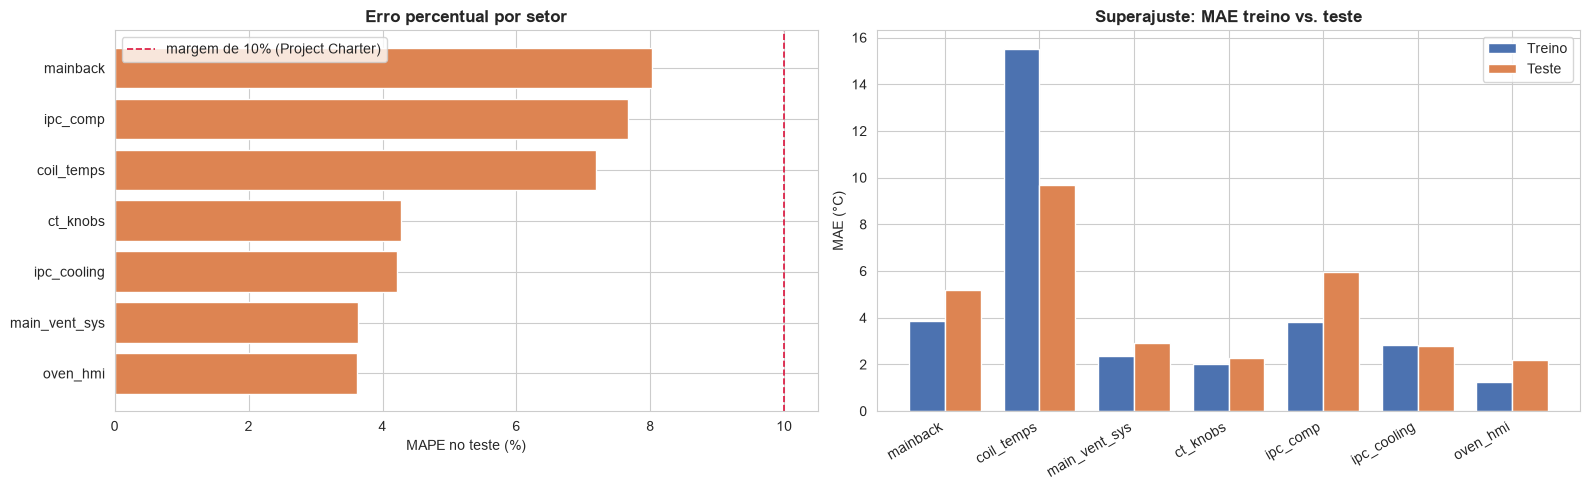

In [9]:
# ============================================================
# CÉLULA 9 — COMPARATIVO ENTRE SETORES
# ============================================================
comparativo = pd.DataFrame(resumos)

print("=" * 130)
print("COMPARATIVO ENTRE SETORES — Decision Tree, métricas médias no conjunto de teste")
print("=" * 130)
print(comparativo.round(4).to_string(index=False))

print("\n" + "=" * 130)
print("MÉDIA ENTRE OS SETORES")
print("=" * 130)
print(comparativo[["MAE_teste", "RMSE_teste", "R2_teste", "MAPE_teste_%", "dentro_de_10%"]]
      .mean().round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ordem = comparativo.sort_values("MAPE_teste_%")
axes[0].barh(ordem["setor"], ordem["MAPE_teste_%"], color="#DD8452")
axes[0].axvline(10, color="crimson", linestyle="--", linewidth=1.2,
                label="margem de 10% (Project Charter)")
axes[0].set_xlabel("MAPE no teste (%)")
axes[0].set_title("Erro percentual por setor", fontsize=12, fontweight="bold")
axes[0].legend()

largura = 0.38
posicoes = np.arange(len(comparativo))
axes[1].bar(posicoes - largura / 2, comparativo["MAE_treino"], largura,
            label="Treino", color="#4C72B0")
axes[1].bar(posicoes + largura / 2, comparativo["MAE_teste"], largura,
            label="Teste", color="#DD8452")
axes[1].set_xticks(posicoes)
axes[1].set_xticklabels(comparativo["setor"], rotation=30, ha="right")
axes[1].set_ylabel("MAE (°C)")
axes[1].set_title("Superajuste: MAE treino vs. teste", fontsize=12, fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.show()

## 10. Decision Tree vs. baseline "média do termopar"

O baseline ignora as sete variáveis de configuração: para cada termopar, ele prevê
sempre a média do treino daquele termopar. É o piso de comparação — se a árvore não
bater isso em uma área, as features não estão agregando informação além da média
histórica naquele setor.

Esta célula também expõe o ranking de MAPE (comparável entre setores) e o gap de
MAE treino → teste (risco de overfitting, R03 da Seção 4.1.5).

In [10]:
# ============================================================
# CÉLULA 10 — DECISION TREE vs. BASELINE "MÉDIA DO TERMOPAR"
# ============================================================
nao_supera_baseline = comparativo[~comparativo["supera_baseline_MAE"]]

print("=" * 130)
print("DECISION TREE vs. BASELINE (MÉDIA DO TERMOPAR NO TREINO) — conjunto de teste")
print("=" * 130)
print(comparativo[["setor", "MAE_teste", "MAE_teste_baseline", "MAPE_teste_%",
                    "MAPE_teste_baseline_%", "supera_baseline_MAE"]]
      .round(4).to_string(index=False))

if len(nao_supera_baseline):
    print("\nATENÇÃO — setores em que a árvore NÃO supera o baseline (MAE_teste >= MAE_teste_baseline):")
    for _, linha in nao_supera_baseline.iterrows():
        print(f"   {linha['setor']:15s} MAE_teste={linha['MAE_teste']:.3f}  "
              f"MAE_baseline={linha['MAE_teste_baseline']:.3f}  "
              f"MAPE_teste={linha['MAPE_teste_%']:.2f}%  MAPE_baseline={linha['MAPE_teste_baseline_%']:.2f}%")
else:
    print("\nA árvore supera o baseline (MAE) em todos os setores.")

print("\n" + "=" * 130)
print("RANKING DE MAPE NO TESTE (menor = melhor; comparável entre setores)")
print("=" * 130)
print(comparativo[["setor", "MAPE_teste_%"]].sort_values("MAPE_teste_%")
      .round(4).to_string(index=False))

print("\n" + "=" * 130)
print("RANKING DE GAP MAE TREINO -> TESTE (maior = mais risco de overfitting)")
print("=" * 130)
print(comparativo[["setor", "MAE_treino", "MAE_teste", "gap_MAE_treino_teste"]]
      .sort_values("gap_MAE_treino_teste", ascending=False).round(4).to_string(index=False))

DECISION TREE vs. BASELINE (MÉDIA DO TERMOPAR NO TREINO) — conjunto de teste
        setor  MAE_teste  MAE_teste_baseline  MAPE_teste_%  MAPE_teste_baseline_%  supera_baseline_MAE
     mainback     5.2031              4.7647        8.0261                 7.2197                False
   coil_temps     9.6794             19.0461        7.1849                13.0031                 True
main_vent_sys     2.9049              2.4940        3.6273                 3.1453                False
     ct_knobs     2.2534              2.5993        4.2767                 5.0223                 True
     ipc_comp     5.9379              3.7661        7.6659                 4.8857                False
  ipc_cooling     2.8054              2.2260        4.2130                 3.2999                False
     oven_hmi     2.1905              1.9633        3.6262                 3.2331                False

ATENÇÃO — setores em que a árvore NÃO supera o baseline (MAE_teste >= MAE_teste_baseline):
   main

## 11. Sensibilidade à semente — o resultado depende do split?

`SEMENTE` (Célula 1) controla a divisão treino/teste/verificação e o desempate entre
splits equivalentes da árvore. Com ~19 linhas por setor, o teste tem só 3-4 linhas e a
verificação 2, então cada semente sorteia um conjunto de teste diferente e o
desempenho varia bastante de uma semente para outra.

Esta seção reexecuta o pipeline das sete áreas (Célula 8) para várias sementes e
mostra a distribuição do desempenho. `treinar_area` agora aceita `semente=` — sem
argumento, continua usando a `SEMENTE` global. O critério de ranking é o **menor MAPE
médio no teste** (comparável entre setores).

**Ressalva sobre "a melhor semente":** escolher a semente que dá o melhor resultado
no teste seleciona o split mais favorável, não o modelo mais correto — o número
deixa de ser uma estimativa honesta de desempenho em dados novos. O gráfico da
direita testa isso: se a semente vencedora no teste também fosse boa na verificação
(linhas que ela não usou na escolha), os pontos formariam uma diagonal.

Além disso, o Random Forest e o Gradient Boosting usam `SEMENTE = 42`. Para a
comparação final, os três modelos precisam avaliar exatamente
as mesmas linhas — trocar a semente só no Decision Tree quebra isso.

10 MELHORES SEMENTES (menor MAPE médio no teste) — média entre os 7 setores, 31 sementes testadas
 semente  MAE_teste  MAPE_teste_%  dentro_de_10%  MAE_verificacao  MAPE_verificacao_%  dentro_de_10%_verificacao
      30     3.3261        4.0055         0.9205           5.4355              7.1510                     0.7709
      22     4.2448        4.4456         0.9188           4.5698              5.6366                     0.8121
      12     3.7090        4.4941         0.9275           3.9080              4.8456                     0.9131
      25     3.9962        4.7671         0.8896           5.0734              6.4137                     0.8325
       9     4.5482        4.7710         0.8723           3.8412              4.7594                     0.8859
      11     4.3369        4.8100         0.8904           4.3284              5.2826                     0.8701
       8     4.4378        4.9119         0.8659           3.1994              3.5911                     0.939

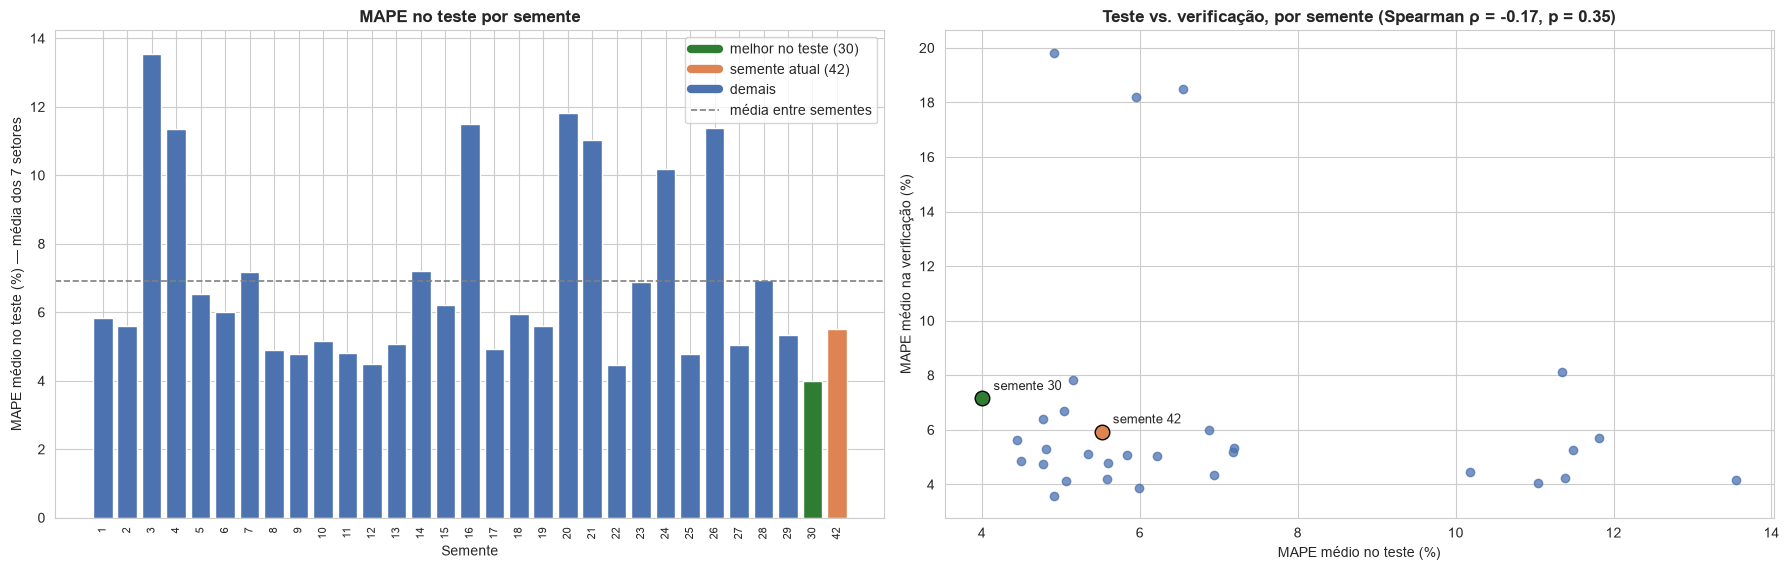

Melhor semente no teste: 30 — MAPE no teste 4.01%, mas 7.15% na verificação.
Semente atual (42): posição 13 de 31 — MAPE no teste 5.52%, 5.93% na verificação.
Entre sementes, o MAPE no teste é 6.90% ± 2.71% (mín. 4.01%, máx. 13.55%).
Correlação de Spearman entre MAPE no teste e na verificação, entre sementes: -0.17 (p = 0.35).
-> Sem relação significativa: ser a melhor semente no teste não prevê ser melhor na verificação. O ganho dessa semente é um split favorável, não um modelo melhor. Reporte a média entre sementes como desempenho esperado.


In [11]:
# ============================================================
# CÉLULA 11 — SENSIBILIDADE À SEMENTE
# Reexecuta as sete áreas (Célula 8) para várias sementes e agrega o desempenho
# médio entre setores por semente.
# ============================================================
from scipy.stats import spearmanr
from matplotlib.lines import Line2D

SEMENTES_TESTADAS = list(range(1, 31))
if SEMENTE not in SEMENTES_TESTADAS:
    SEMENTES_TESTADAS.append(SEMENTE)

from joblib import Parallel, delayed


def rodar_semente(semente_teste):
    """Treina as sete áreas com uma semente. Roda em um processo separado."""
    resumos, falhas = [], []
    for caminho in PLANILHAS:
        try:
            resumo_s, _ = treinar_area(caminho, semente=semente_teste)
            resumos.append({**resumo_s, "semente": semente_teste})
        except Exception as erro:
            falhas.append(f"FALHA semente={semente_teste} {caminho}: {type(erro).__name__}: {erro}")
    return resumos, falhas


# Cada semente é independente das demais: uma por processo, usando todos os núcleos.
# O resultado é o mesmo do laço em série; muda só o tempo (~1/6 em 12 núcleos).
resultados_por_semente = Parallel(n_jobs=-1)(
    delayed(rodar_semente)(semente_teste) for semente_teste in SEMENTES_TESTADAS
)

linhas_semente = []
todas_linhas_semente = []
for semente_teste, (resumos_semente, falhas) in zip(SEMENTES_TESTADAS, resultados_por_semente):
    for mensagem in falhas:
        print(mensagem)
    todas_linhas_semente.extend(resumos_semente)

    media_setores = pd.DataFrame(resumos_semente).mean(numeric_only=True)
    linhas_semente.append({
        "semente": semente_teste,
        "MAE_teste": media_setores["MAE_teste"],
        "MAPE_teste_%": media_setores["MAPE_teste_%"],
        "dentro_de_10%": media_setores["dentro_de_10%"],
        "MAE_verificacao": media_setores["MAE_verificacao"],
        "MAPE_verificacao_%": media_setores["MAPE_verificacao_%"],
        "dentro_de_10%_verificacao": media_setores["dentro_de_10%_verificacao"],
    })

sensibilidade_semente = pd.DataFrame(linhas_semente).sort_values("semente", ignore_index=True)
ranking_semente = sensibilidade_semente.sort_values("MAPE_teste_%", ignore_index=True)
melhor_semente = int(ranking_semente.loc[0, "semente"])
posicao_padrao = int(ranking_semente.index[ranking_semente["semente"] == SEMENTE][0]) + 1

print("=" * 110)
print(f"10 MELHORES SEMENTES (menor MAPE médio no teste) — média entre os 7 setores, "
      f"{len(SEMENTES_TESTADAS)} sementes testadas")
print("=" * 110)
print(ranking_semente.head(10).round(4).to_string(index=False))

print("\n" + "=" * 110)
print("DISTRIBUIÇÃO ENTRE SEMENTES (média, desvio padrão, mínimo, máximo)")
print("=" * 110)
colunas_dist = ["MAE_teste", "MAPE_teste_%", "dentro_de_10%",
                "MAE_verificacao", "MAPE_verificacao_%", "dentro_de_10%_verificacao"]
print(sensibilidade_semente[colunas_dist].agg(["mean", "std", "min", "max"]).T.round(4).to_string())

rho, p_rho = spearmanr(sensibilidade_semente["MAPE_teste_%"],
                       sensibilidade_semente["MAPE_verificacao_%"])

fig, axes = plt.subplots(1, 2, figsize=(18, 5.8))

cores = ["#2E7D32" if s == melhor_semente else "#DD8452" if s == SEMENTE else "#4C72B0"
         for s in sensibilidade_semente["semente"]]
axes[0].bar(sensibilidade_semente["semente"].astype(str),
            sensibilidade_semente["MAPE_teste_%"], color=cores)
axes[0].axhline(sensibilidade_semente["MAPE_teste_%"].mean(), color="gray", linestyle="--",
                linewidth=1.2)
axes[0].set_xlabel("Semente")
axes[0].set_ylabel("MAPE médio no teste (%) — média dos 7 setores")
axes[0].set_title("MAPE no teste por semente", fontsize=12, fontweight="bold")
axes[0].tick_params(axis="x", labelrotation=90, labelsize=8)
axes[0].legend(handles=[
    Line2D([0], [0], color="#2E7D32", lw=6, label=f"melhor no teste ({melhor_semente})"),
    Line2D([0], [0], color="#DD8452", lw=6, label=f"semente atual ({SEMENTE})"),
    Line2D([0], [0], color="#4C72B0", lw=6, label="demais"),
    Line2D([0], [0], color="gray", lw=1.2, linestyle="--", label="média entre sementes"),
])

axes[1].scatter(sensibilidade_semente["MAPE_teste_%"], sensibilidade_semente["MAPE_verificacao_%"],
                color="#4C72B0", alpha=0.75)
for semente_destaque, cor in [(melhor_semente, "#2E7D32"), (SEMENTE, "#DD8452")]:
    linha = sensibilidade_semente[sensibilidade_semente["semente"] == semente_destaque].iloc[0]
    axes[1].scatter(linha["MAPE_teste_%"], linha["MAPE_verificacao_%"], color=cor, s=110,
                    edgecolor="black", zorder=3)
    axes[1].annotate(f"semente {semente_destaque}", (linha["MAPE_teste_%"], linha["MAPE_verificacao_%"]),
                     textcoords="offset points", xytext=(8, 6), fontsize=9)
axes[1].set_xlabel("MAPE médio no teste (%)")
axes[1].set_ylabel("MAPE médio na verificação (%)")
axes[1].set_title(f"Teste vs. verificação, por semente (Spearman ρ = {rho:+.2f}, p = {p_rho:.2f})",
                  fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig("../assets/graficos/dt_sensibilidade_semente.png", dpi=150, bbox_inches="tight")
plt.show()

linha_melhor = sensibilidade_semente[sensibilidade_semente["semente"] == melhor_semente].iloc[0]
linha_padrao = sensibilidade_semente[sensibilidade_semente["semente"] == SEMENTE].iloc[0]
media_mape = sensibilidade_semente["MAPE_teste_%"].mean()
desvio_mape = sensibilidade_semente["MAPE_teste_%"].std()

print(f"Melhor semente no teste: {melhor_semente} — MAPE no teste {linha_melhor['MAPE_teste_%']:.2f}%, "
      f"mas {linha_melhor['MAPE_verificacao_%']:.2f}% na verificação.")
print(f"Semente atual ({SEMENTE}): posição {posicao_padrao} de {len(SEMENTES_TESTADAS)} — "
      f"MAPE no teste {linha_padrao['MAPE_teste_%']:.2f}%, {linha_padrao['MAPE_verificacao_%']:.2f}% na verificação.")
print(f"Entre sementes, o MAPE no teste é {media_mape:.2f}% ± {desvio_mape:.2f}% "
      f"(mín. {sensibilidade_semente['MAPE_teste_%'].min():.2f}%, máx. {sensibilidade_semente['MAPE_teste_%'].max():.2f}%).")
print(f"Correlação de Spearman entre MAPE no teste e na verificação, entre sementes: "
      f"{rho:+.2f} (p = {p_rho:.2f}).")
if p_rho >= 0.05:
    print("-> Sem relação significativa: ser a melhor semente no teste não prevê ser melhor na "
          "verificação. O ganho dessa semente é um split favorável, não um modelo melhor. "
          "Reporte a média entre sementes como desempenho esperado.")
else:
    print(f"-> Há relação estatisticamente significativa (rho = {rho:+.2f}) entre teste e verificação "
          f"nas sementes testadas; ainda assim, o resultado de uma semente escolhida pelo teste é "
          f"otimista — reporte a média entre sementes como desempenho esperado.")

## 12. Árvore vs. baseline "média do termopar" entre sementes

Usa as linhas (semente × setor) guardadas na Célula 11, sem treinar nada de novo. Com
uma única semente, a comparação com o baseline depende do split sorteado; aqui ela é
feita sobre 31 sementes × 7 setores = 217 casos, com o teste de Wilcoxon pareado
(mesmas linhas de teste para árvore e baseline em cada caso).

A frequência de vitórias mostra **onde** a árvore agrega informação além da média
histórica do setor: valores próximos de 50% indicam que ela e o baseline são
indistinguíveis naquele setor.

ÁRVORE vs. BASELINE — 217 casos (31 sementes x 7 setores)
                   Árvore  Baseline
MAE (°C)            5.361     6.224
MAPE (%)            6.902     7.557
dentro de 10% (%)  82.304    81.771
R² (mediana)       -1.067    -0.859

Árvore vence o baseline em MAE em 114 de 217 casos (52.5%). Wilcoxon: diferença média de MAE = +0.863 °C a favor da árvore, p = 0.1878.
R²: casos com R² > 0 — árvore 5.5%, baseline 0.0%. Wilcoxon: diferença mediana de R² = -0.188 (árvore − baseline), p = 0.0000.

POR SETOR (média entre sementes):
        setor  MAE_arvore  MAE_arvore_desvio  MAE_baseline  MAE_baseline_desvio  vitorias_arvore_pct
   coil_temps      17.671              7.520        24.220                7.635               96.774
     mainback       4.150              2.457         4.547                2.175               74.194
  ipc_cooling       3.201              0.655         3.156                0.638               54.839
     ct_knobs       2.509              0.623         2.359 

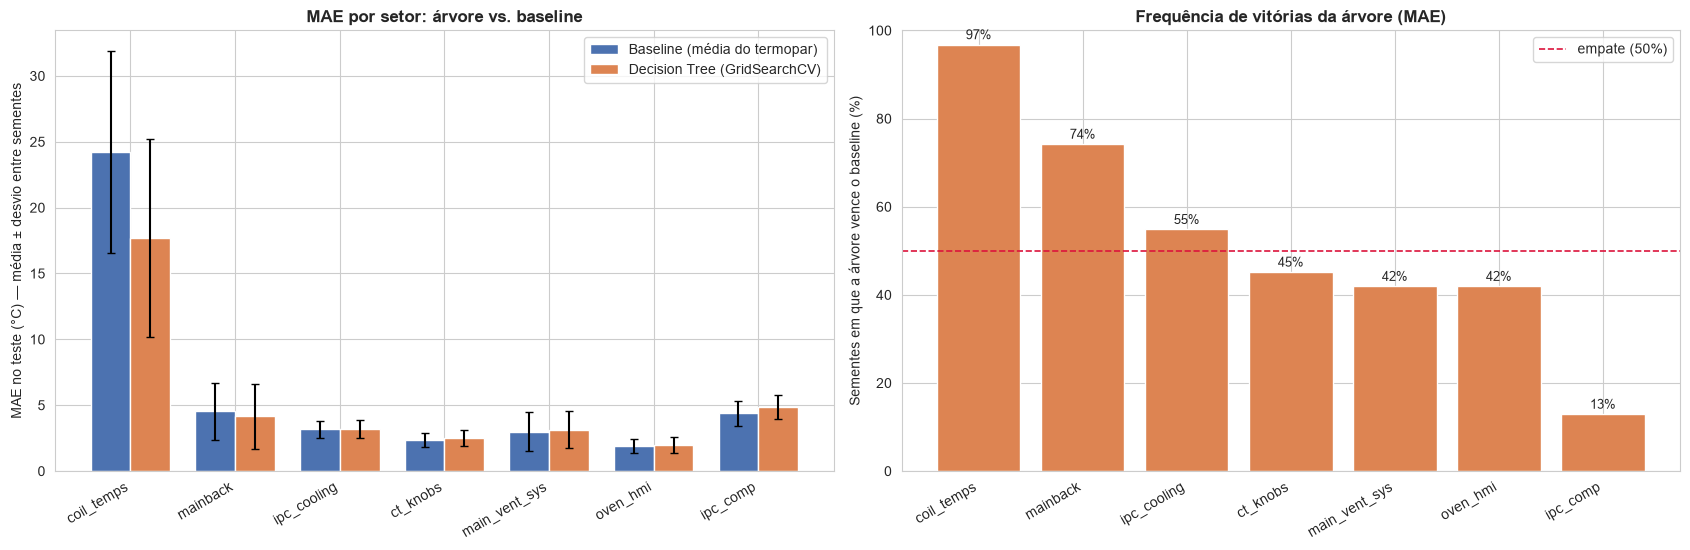

In [12]:
# ============================================================
# CÉLULA 12 — ÁRVORE vs. BASELINE "MÉDIA DO TERMOPAR" ENTRE SEMENTES
# ============================================================
from scipy.stats import wilcoxon

casos = pd.DataFrame(todas_linhas_semente)
casos["arvore_vence_MAE"] = casos["MAE_teste"] < casos["MAE_teste_baseline"]

por_setor_semente = (
    casos.groupby("setor")
         .agg(MAE_arvore=("MAE_teste", "mean"), MAE_arvore_desvio=("MAE_teste", "std"),
              MAE_baseline=("MAE_teste_baseline", "mean"), MAE_baseline_desvio=("MAE_teste_baseline", "std"),
              vitorias_arvore_pct=("arvore_vence_MAE", lambda s: s.mean() * 100))
         .reset_index()
         .sort_values("vitorias_arvore_pct", ascending=False, ignore_index=True)
)

resumo_geral = pd.DataFrame({
    "Árvore": [casos["MAE_teste"].mean(), casos["MAPE_teste_%"].mean(),
               casos["dentro_de_10%"].mean() * 100, casos["R2_teste"].median()],
    "Baseline": [casos["MAE_teste_baseline"].mean(), casos["MAPE_teste_baseline_%"].mean(),
                 casos["dentro_de_10%_baseline"].mean() * 100, casos["R2_teste_baseline"].median()],
}, index=["MAE (°C)", "MAPE (%)", "dentro de 10% (%)", "R² (mediana)"])

_, p_mae = wilcoxon(casos["MAE_teste"], casos["MAE_teste_baseline"])
_, p_r2 = wilcoxon(casos["R2_teste"], casos["R2_teste_baseline"])
dif_mae = (casos["MAE_teste_baseline"] - casos["MAE_teste"]).mean()
dif_r2 = (casos["R2_teste"] - casos["R2_teste_baseline"]).median()

print("=" * 100)
print(f"ÁRVORE vs. BASELINE — {len(casos)} casos ({casos['semente'].nunique()} sementes x {casos['setor'].nunique()} setores)")
print("=" * 100)
print(resumo_geral.round(3).to_string())
print(f"\nÁrvore vence o baseline em MAE em {casos['arvore_vence_MAE'].sum()} de {len(casos)} casos "
      f"({casos['arvore_vence_MAE'].mean():.1%}). Wilcoxon: diferença média de MAE = {dif_mae:+.3f} °C "
      f"a favor da árvore, p = {p_mae:.4f}.")
print(f"R²: casos com R² > 0 — árvore {(casos['R2_teste'] > 0).mean():.1%}, "
      f"baseline {(casos['R2_teste_baseline'] > 0).mean():.1%}. Wilcoxon: diferença mediana de R² = "
      f"{dif_r2:+.3f} (árvore − baseline), p = {p_r2:.4f}.")
print("\nPOR SETOR (média entre sementes):")
print(por_setor_semente.round(3).to_string(index=False))

posicoes_setor = np.arange(len(por_setor_semente))
fig, axes = plt.subplots(1, 2, figsize=(17, 5.6))

axes[0].bar(posicoes_setor - 0.19, por_setor_semente["MAE_baseline"], 0.38,
            yerr=por_setor_semente["MAE_baseline_desvio"], capsize=3,
            label="Baseline (média do termopar)", color="#4C72B0")
axes[0].bar(posicoes_setor + 0.19, por_setor_semente["MAE_arvore"], 0.38,
            yerr=por_setor_semente["MAE_arvore_desvio"], capsize=3,
            label="Decision Tree (GridSearchCV)", color="#DD8452")
axes[0].set_xticks(posicoes_setor)
axes[0].set_xticklabels(por_setor_semente["setor"], rotation=30, ha="right")
axes[0].set_ylabel("MAE no teste (°C) — média ± desvio entre sementes")
axes[0].set_title("MAE por setor: árvore vs. baseline", fontsize=12, fontweight="bold")
axes[0].legend()

barras_vitorias = axes[1].bar(posicoes_setor, por_setor_semente["vitorias_arvore_pct"], color="#DD8452")
axes[1].bar_label(barras_vitorias, fmt="%.0f%%", padding=2, fontsize=9)
axes[1].axhline(50, color="crimson", linestyle="--", linewidth=1.2, label="empate (50%)")
axes[1].set_xticks(posicoes_setor)
axes[1].set_xticklabels(por_setor_semente["setor"], rotation=30, ha="right")
axes[1].set_ylabel("Sementes em que a árvore vence o baseline (%)")
axes[1].set_ylim(0, 100)
axes[1].set_title("Frequência de vitórias da árvore (MAE)", fontsize=12, fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.savefig("../assets/graficos/dt_vs_baseline_sementes.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Antes vs. depois do tuning — comparação de erro

A Célula 5 já define a grade de hiperparâmetros do `GridSearchCV` (`max_depth`,
`min_samples_split`, `min_samples_leaf`, `max_features`) como controle de
complexidade — a escolha adequada para uma árvore única treinada em poucas dezenas
de linhas por setor, onde o risco dominante é a árvore decorar o treino. Dois
hiperparâmetros adicionais foram avaliados e descartados da grade, em vez de
simplesmente omitidos sem justificativa:

- **`criterion`** (`squared_error` / `friedman_mse` / `absolute_error`): tem efeito
  marginal com tão poucas linhas e triplicaria o custo da busca sem ganho
  relevante de MAE.
- **`ccp_alpha`** (poda por custo-complexidade): testado e descartado, agora por um
  motivo medido — seu efeito depende da escala da temperatura de cada setor e, na
  validação cruzada, ele escolhia podar a árvore até **uma folha única** (mainback,
  semente 42), o que equivale a prever a média e elimina o superajuste só porque o
  modelo deixa de usar as variáveis. `max_depth <= 3` e `min_samples_leaf >= 2`
  limitam o tamanho sem esse efeito.

Esta seção isola o efeito do tuning em si: treina, para cada `key_area`, uma árvore
com os hiperparâmetros **default** do scikit-learn ("antes") na mesma divisão
treino/teste/verificação (mesmo `SEMENTE`) usada pela Célula 8, e compara com o
`best_estimator_` do `GridSearchCV` ("depois") já treinado naquela célula — sem
alterar `preparar_area`, `identificar_alvos`, `codificar_one_hot` ou
`avaliar_multioutput`.

In [13]:

# ============================================================
# CÉLULA 13 — ANTES (SEM TUNING) vs. DEPOIS (GRIDSEARCHCV)
# Mesma divisão treino/teste/verificação da Célula 8 (mesmo SEMENTE),
# trocando só o estimador: DecisionTreeRegressor default vs. best_estimator_
# do GridSearchCV. Isola o efeito do tuning das demais etapas do pipeline.
# ============================================================
def treinar_area_sem_tuning(caminho, semente=None):
    """Réplica da divisão/avaliação da Célula 8, com hiperparâmetros default
    (sem GridSearchCV) — baseline "antes do tuning" para a mesma key_area."""
    semente = SEMENTE if semente is None else semente
    X_area, Y_area, alvos, dicionario, removidos, linhas_originais = preparar_area(caminho)

    if len(X_area) < MINIMO_DE_LINHAS:
        raise ValueError(f"{caminho}: apenas {len(X_area)} linhas úteis")

    X_tr, X_resto, Y_tr, Y_resto = train_test_split(
        X_area, Y_area, train_size=PROPORCAO_TREINO, random_state=semente)
    X_te, X_ve, Y_te, Y_ve = train_test_split(
        X_resto, Y_resto,
        test_size=PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO),
        random_state=semente)

    modelo_sem_tuning = DecisionTreeRegressor(random_state=semente).fit(X_tr, Y_tr)

    previsoes_tr = modelo_sem_tuning.predict(X_tr)
    previsoes_te = modelo_sem_tuning.predict(X_te)
    previsoes_ve = modelo_sem_tuning.predict(X_ve)

    metricas = pd.DataFrame(
        avaliar_multioutput(Y_tr, previsoes_tr, "Treino", alvos)
      + avaliar_multioutput(Y_te, previsoes_te, "Teste", alvos)
      + avaliar_multioutput(Y_ve, previsoes_ve, "Verificação", alvos)
    )
    medias = metricas.groupby("conjunto", sort=False)[["MAE", "RMSE", "R2", "MAPE_%"]].mean()

    return {
        "setor": caminho.split("/")[-1].replace("_data.csv", ""),
        "profundidade_antes": modelo_sem_tuning.get_depth(),
        "folhas_antes": int(modelo_sem_tuning.get_n_leaves()),
        "MAE_treino_antes": medias.loc["Treino", "MAE"],
        "MAE_teste_antes": medias.loc["Teste", "MAE"],
        "RMSE_teste_antes": medias.loc["Teste", "RMSE"],
        "R2_teste_antes": medias.loc["Teste", "R2"],
        "MAPE_teste_antes_%": medias.loc["Teste", "MAPE_%"],
        "MAE_verificacao_antes": medias.loc["Verificação", "MAE"],
        "RMSE_verificacao_antes": medias.loc["Verificação", "RMSE"],
    }


resumos_antes = []
for caminho in PLANILHAS:
    try:
        resumos_antes.append(treinar_area_sem_tuning(caminho))
    except Exception as erro:
        print(f"FALHA {caminho}: {type(erro).__name__}: {erro}")

antes = pd.DataFrame(resumos_antes)


def melhores_hiperparametros(setor):
    """Extrai só as chaves da grade tunada a partir do best_estimator_ guardado em MODELOS_POR_AREA."""
    parametros = MODELOS_POR_AREA[setor]["modelo"].get_params()
    return {chave: parametros[chave] for chave in GRADE_HIPERPARAMETROS}


depois = comparativo[[
    "setor", "profundidade", "folhas", "MAE_treino", "MAE_teste",
    "RMSE_teste", "R2_teste", "MAPE_teste_%", "MAE_verificacao", "RMSE_verificacao",
]].rename(columns={
    "profundidade": "profundidade_depois",
    "folhas": "folhas_depois",
    "MAE_treino": "MAE_treino_depois",
    "MAE_teste": "MAE_teste_depois",
    "RMSE_teste": "RMSE_teste_depois",
    "R2_teste": "R2_teste_depois",
    "MAPE_teste_%": "MAPE_teste_depois_%",
    "MAE_verificacao": "MAE_verificacao_depois",
    "RMSE_verificacao": "RMSE_verificacao_depois",
})
depois["melhores_hiperparametros"] = depois["setor"].map(melhores_hiperparametros)

antes_depois = antes.merge(depois, on="setor")
antes_depois["reducao_MAE_teste_%"] = (
    (antes_depois["MAE_teste_antes"] - antes_depois["MAE_teste_depois"])
    / antes_depois["MAE_teste_antes"] * 100
)
antes_depois["reducao_gap_overfitting"] = (
    (antes_depois["MAE_teste_antes"] - antes_depois["MAE_treino_antes"])
  - (antes_depois["MAE_teste_depois"] - antes_depois["MAE_treino_depois"])
)

print("=" * 130)
print("DECISION TREE — ANTES (hiperparâmetros default) vs. DEPOIS (GridSearchCV)")
print("=" * 130)
COLUNAS_RESUMO = [
    "setor", "MAE_teste_antes", "MAE_teste_depois", "reducao_MAE_teste_%",
    "RMSE_teste_antes", "RMSE_teste_depois",
    "R2_teste_antes", "R2_teste_depois",
    "MAPE_teste_antes_%", "MAPE_teste_depois_%",
    "melhores_hiperparametros",
]
print(antes_depois[COLUNAS_RESUMO].round(4).to_string(index=False))

print("\n" + "=" * 130)
print("MÉDIA ENTRE OS SETORES")
print("=" * 130)
print(antes_depois[[
    "MAE_teste_antes", "MAE_teste_depois",
    "RMSE_teste_antes", "RMSE_teste_depois",
    "R2_teste_antes", "R2_teste_depois",
    "MAPE_teste_antes_%", "MAPE_teste_depois_%",
]].mean().round(4).to_string())


DECISION TREE — ANTES (hiperparâmetros default) vs. DEPOIS (GridSearchCV)
        setor  MAE_teste_antes  MAE_teste_depois  reducao_MAE_teste_%  RMSE_teste_antes  RMSE_teste_depois  R2_teste_antes  R2_teste_depois  MAPE_teste_antes_%  MAPE_teste_depois_%                                        melhores_hiperparametros
     mainback           2.5633            5.2031            -102.9798            3.2248             6.9978         -1.1567          -1.4522              4.0425               8.0261 {'max_depth': 1, 'min_samples_leaf': 4, 'min_samples_split': 8}
   coil_temps           9.2841            9.6794              -4.2581           12.4547            12.0711         -3.3110          -7.3089              7.0581               7.1849 {'max_depth': 1, 'min_samples_leaf': 3, 'min_samples_split': 8}
main_vent_sys           1.8230            2.9049             -59.3479            2.3514             4.3666         -1.0309          -0.8767              2.4009               3.6273 {'max_dept

## 14. Gráficos — erro antes vs. depois do tuning, por setor

MAE, MSE, RMSE, R² e MAPE no conjunto de teste, lado a lado por `key_area`
(grade 2×3, último painel vazio). A paleta é a mesma azul/laranja
(`#4C72B0`/`#DD8452`) usada na Célula 9 para manter consistência visual com o
resto do notebook — aqui o par passa a significar "antes"/"depois" do tuning,
não "treino"/"teste". O painel de MAPE mantém a linha de referência de 10%
(margem do Project Charter).

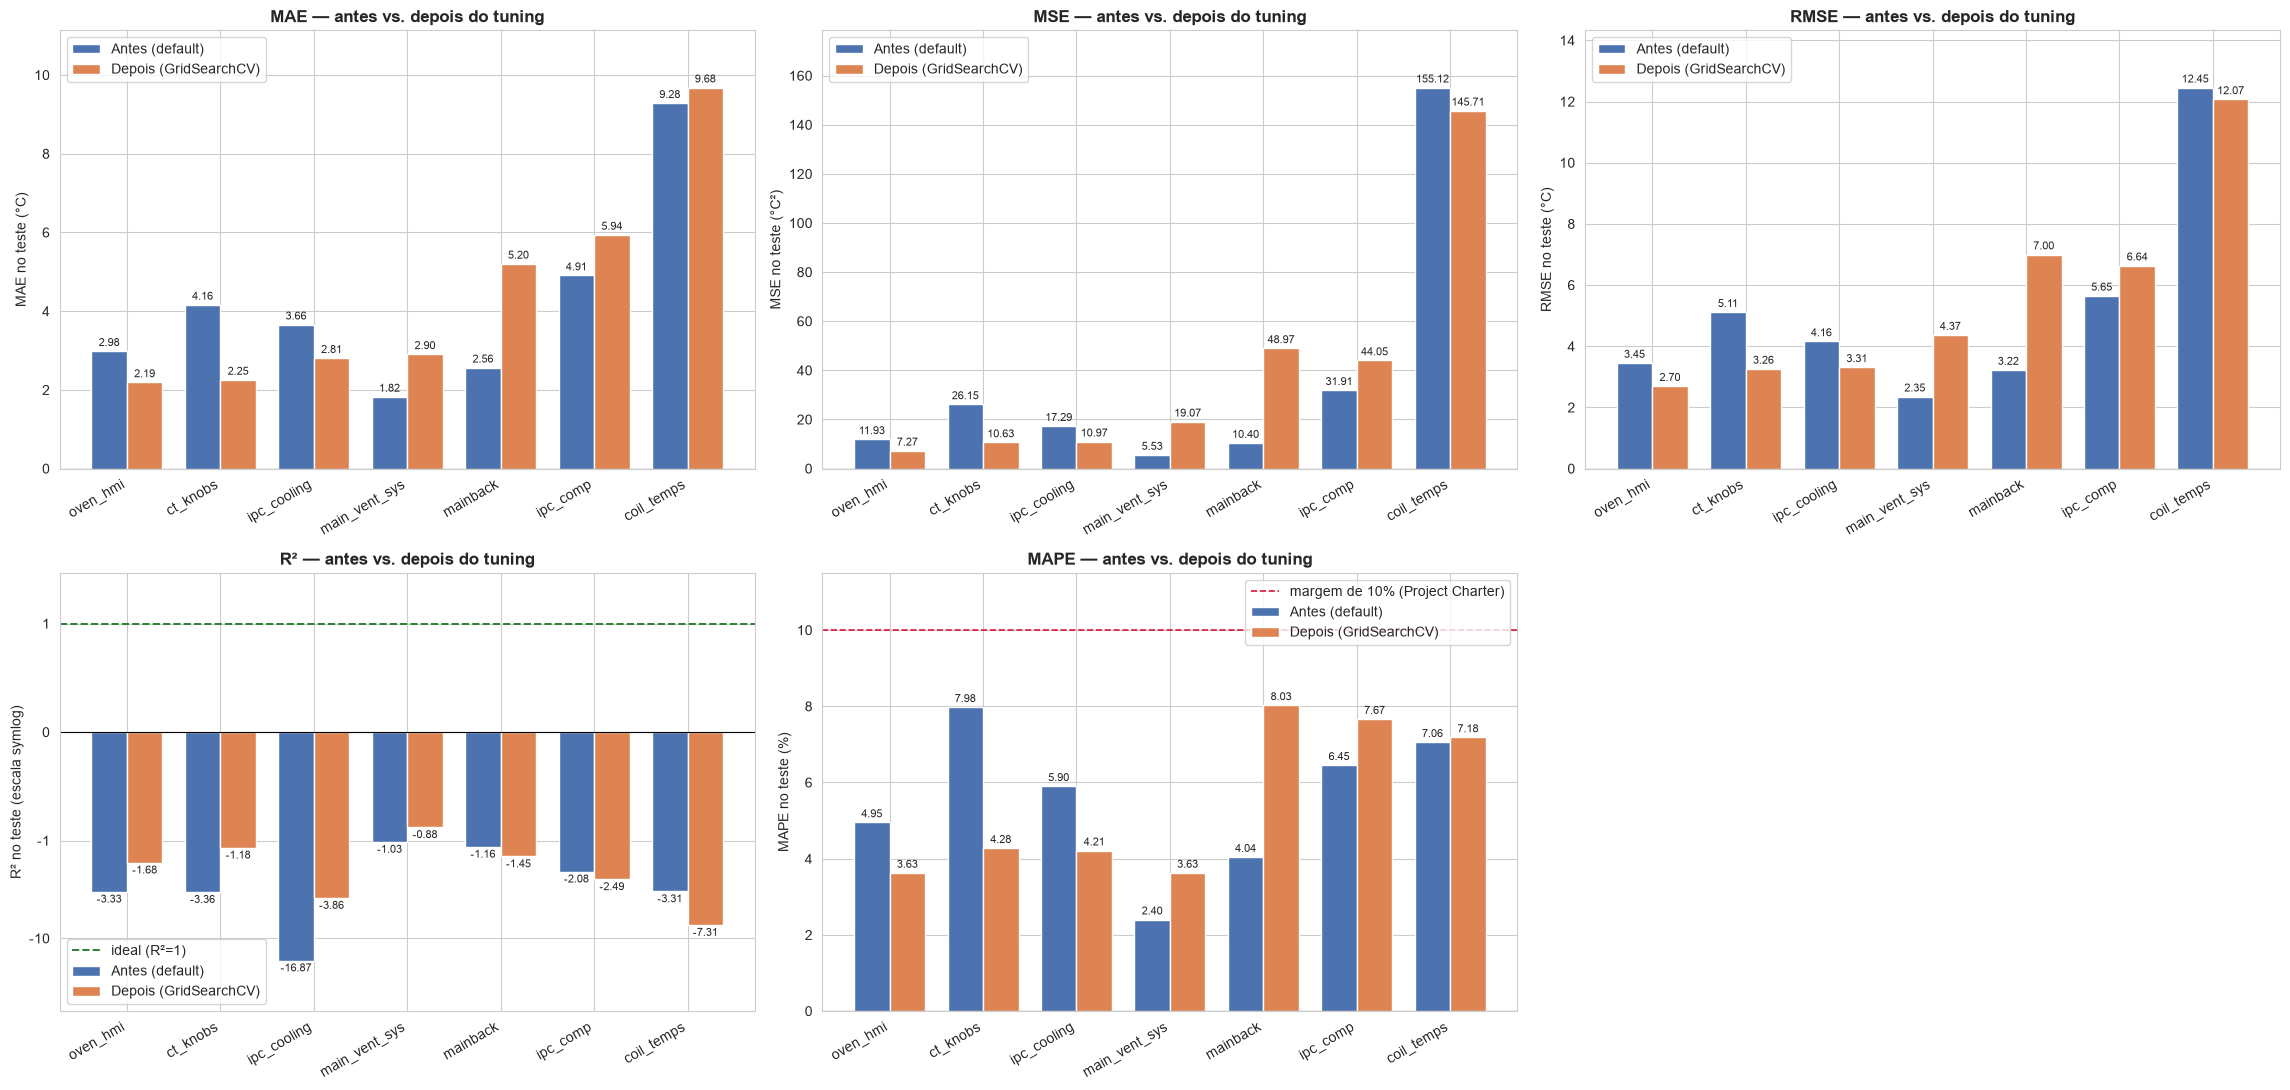

In [14]:

# ============================================================
# CÉLULA 14 — GRÁFICOS: ERRO ANTES vs. DEPOIS DO TUNING, POR SETOR
# MAE, MSE, RMSE, R² e MAPE lado a lado, com o valor de cada barra anotado.
# MSE = RMSE² (não precisa recalcular — é derivado diretamente do RMSE já
# presente em antes_depois).
#
# O painel de R² usa escala symlog (logarítmica simétrica, aceita negativos):
# setores com R² muito negativo (ex. -77) esticavam o eixo Y a ponto de a
# diferença entre os outros setores — e a distância até o ideal (R²=1) —
# ficar ilegível numa escala linear comum. Os rótulos do eixo são forçados a
# número simples (1, 10, 100...) em vez da notação "10^0" padrão do symlog.
# ============================================================
from matplotlib.ticker import FuncFormatter

ordem_setores = antes_depois.sort_values("MAE_teste_depois")["setor"]
plot_df = antes_depois.set_index("setor").loc[ordem_setores].copy()

plot_df["MSE_teste_antes"] = plot_df["RMSE_teste_antes"] ** 2
plot_df["MSE_teste_depois"] = plot_df["RMSE_teste_depois"] ** 2

largura = 0.38
posicoes = np.arange(len(plot_df))

fig, axes = plt.subplots(2, 3, figsize=(23, 11))

# (coluna_antes, coluna_depois, ylabel, título, linha_de_referência, escala_symlog)
metricas_grafico = [
    ("MAE_teste_antes", "MAE_teste_depois", "MAE no teste (°C)", "MAE — antes vs. depois do tuning", None, False),
    ("MSE_teste_antes", "MSE_teste_depois", "MSE no teste (°C²)", "MSE — antes vs. depois do tuning", None, False),
    ("RMSE_teste_antes", "RMSE_teste_depois", "RMSE no teste (°C)", "RMSE — antes vs. depois do tuning", None, False),
    ("R2_teste_antes", "R2_teste_depois", "R² no teste (escala symlog)", "R² — antes vs. depois do tuning", 1, True),
    ("MAPE_teste_antes_%", "MAPE_teste_depois_%", "MAPE no teste (%)", "MAPE — antes vs. depois do tuning", 10, False),
]

for ax, (col_antes, col_depois, ylabel, titulo, linha_referencia, usar_symlog) in zip(axes.flat, metricas_grafico):
    barras_antes = ax.bar(posicoes - largura / 2, plot_df[col_antes], largura,
                           label="Antes (default)", color="#4C72B0")
    barras_depois = ax.bar(posicoes + largura / 2, plot_df[col_depois], largura,
                            label="Depois (GridSearchCV)", color="#DD8452")
    ax.bar_label(barras_antes, fmt="%.2f", fontsize=8, padding=2)
    ax.bar_label(barras_depois, fmt="%.2f", fontsize=8, padding=2)
    ax.axhline(0, color="black", linewidth=0.8)

    if usar_symlog:
        ax.set_yscale("symlog", linthresh=1)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}"))
        ax.axhline(linha_referencia, color="#2E7D32", linestyle="--", linewidth=1.4,
                   label="ideal (R²=1)")
    elif linha_referencia is not None:
        ax.axhline(linha_referencia, color="crimson", linestyle="--", linewidth=1.2,
                   label="margem de 10% (Project Charter)")

    ax.set_xticks(posicoes)
    ax.set_xticklabels(plot_df.index, rotation=30, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.margins(y=0.15)
    ax.legend()

# Painel extra (2x3 = 6 posições, só 5 métricas) fica escondido.
axes.flat[-1].axis("off")

plt.tight_layout()
plt.savefig("../assets/graficos/dt_antes_depois_tuning.png", dpi=150, bbox_inches="tight")
plt.show()


## 15. Interpretação dos resultados

Texto gerado a partir de `antes_depois` — não é uma conclusão fixa, reflete os
números calculados acima a cada execução.

In [15]:

# ============================================================
# CÉLULA 15 — INTERPRETAÇÃO DOS RESULTADOS
# ============================================================
maior_reducao = antes_depois.loc[antes_depois["reducao_MAE_teste_%"].idxmax()]
menor_reducao = antes_depois.loc[antes_depois["reducao_MAE_teste_%"].idxmin()]
piorou = antes_depois[antes_depois["reducao_MAE_teste_%"] < 0]
reduziu_overfitting = int((antes_depois["reducao_gap_overfitting"] > 0).sum())

print(f"O tuning reduziu mais o erro em {maior_reducao['setor']} "
      f"(MAE no teste caiu {maior_reducao['reducao_MAE_teste_%']:.1f}%, "
      f"de {maior_reducao['MAE_teste_antes']:.2f} para "
      f"{maior_reducao['MAE_teste_depois']:.2f} °C).")

print(f"Em {reduziu_overfitting} de {len(antes_depois)} setores o gap "
      f"MAE treino -> teste diminuiu após o tuning, indicando menos superajuste "
      f"com os hiperparâmetros escolhidos pelo GridSearchCV.")

if len(piorou):
    setores_piorou = ", ".join(piorou["setor"])
    print(f"Em {setores_piorou} o tuning não reduziu o MAE de teste "
          f"(variação de {menor_reducao['reducao_MAE_teste_%']:.1f}% em "
          f"{menor_reducao['setor']}) — sinal de que, com poucos dados nesses "
          f"setores, o default já estava perto do ponto de equilíbrio, ou de que "
          f"a divisão treino/teste específica favoreceu por acaso o modelo default.")
else:
    print(f"O tuning reduziu o MAE de teste em todos os {len(antes_depois)} "
          f"setores (redução mínima de {menor_reducao['reducao_MAE_teste_%']:.1f}% "
          f"em {menor_reducao['setor']}).")


O tuning reduziu mais o erro em ct_knobs (MAE no teste caiu 45.8%, de 4.16 para 2.25 °C).
Em 7 de 7 setores o gap MAE treino -> teste diminuiu após o tuning, indicando menos superajuste com os hiperparâmetros escolhidos pelo GridSearchCV.
Em mainback, coil_temps, main_vent_sys, ipc_comp o tuning não reduziu o MAE de teste (variação de -103.0% em mainback) — sinal de que, com poucos dados nesses setores, o default já estava perto do ponto de equilíbrio, ou de que a divisão treino/teste específica favoreceu por acaso o modelo default.


## 16. Experimentos de redução de overfitting

Resumo dos três experimentos que levaram às escolhas da Célula 5 (grade restrita,
validação cruzada repetida, one-hot e regra do 1 erro-padrão). Os resultados vêm de
`resultados_experimentos_overfitting.csv`; **os experimentos não são reexecutados aqui**
(levaram de 18 a 31 minutos cada).

**Protocolo (igual nos três):** 19 linhas por setor, 7 setores; para cada semente, o
mesmo split 70/20/10 para todas as variantes; o erro "fora do treino" é o MAE nas 6
linhas de teste + verificação; o **gap** é o MAE fora do treino menos o MAE de treino
(overfitting). Cada experimento é comparado com a sua própria referência
(pareado, Wilcoxon), **sem correção para múltiplas comparações**.

**Cores:** azul = referência do experimento; laranja = variante adotada; cinza = testada
e não adotada; cinza-escuro = baseline "média do treino".

**Validade:** as medidas valem para a base atual (19 linhas por setor, 2026-09-21). Se os
dados mudarem, os experimentos precisam ser refeitos; do contrário esta seção fica
defasada. O experimento 1 foi feito com codificação ordinal (antes do one-hot); o 2
compara as codificações; o 3 já parte do one-hot.

1. Grade e validação cruzada (30 sementes)
                       variante      papel  MAE_fora_treino  delta_MAE_vs_ref p_MAE  gap_treino_fora  delta_gap_vs_ref p_gap  razao_MAE_baseline  vence_baseline_pct
    A: grade original (3 folds) referencia            5.669             0.000     -            3.471             0.000     -               1.044                47.1
B: grade restrita + CV repetida    adotada            5.996             0.327     -            2.059            -1.412     -               1.045                37.6
        C: B + poda (ccp_alpha)    testada            5.910             0.241     -            1.858            -1.613     -               1.023                30.0
          D: fixa d=2, folha>=3    testada            6.192             0.523     -            2.230            -1.241     -               1.088                34.3
          E: fixa d=2, folha>=4    testada            6.202             0.533     -            1.735            -1.736     -        

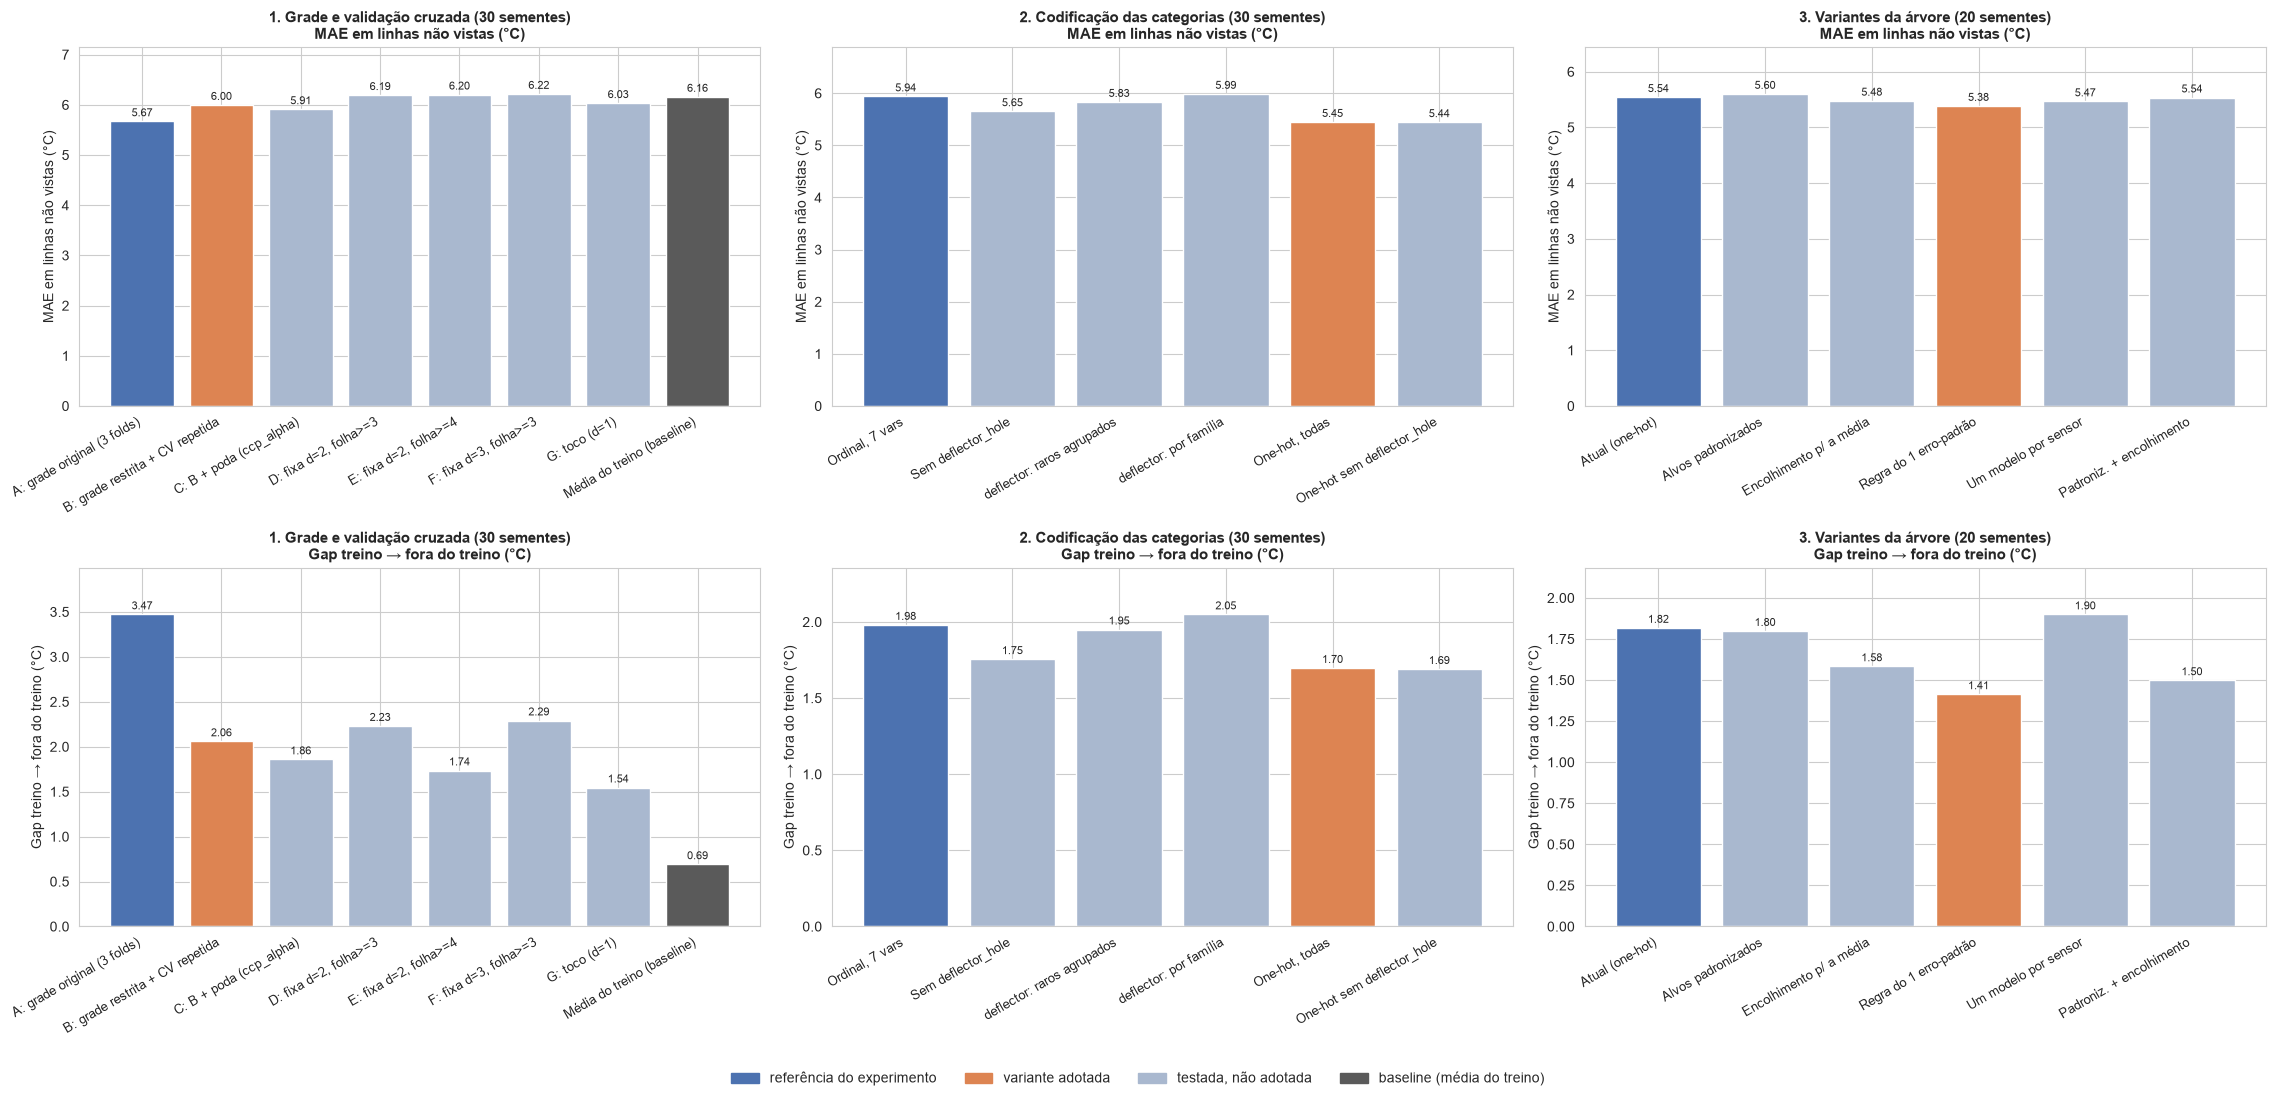

Leitura rápida (menor valor entre as variantes que não são baseline):
   1. Grade e validação cruzada (30 sementes)
      menor MAE fora do treino: A: grade original (3 folds) (5.67 °C)
      menor gap:                G: toco (d=1) (+1.54 °C)
   2. Codificação das categorias (30 sementes)
      menor MAE fora do treino: One-hot sem deflector_hole (5.44 °C)
      menor gap:                One-hot sem deflector_hole (+1.69 °C)
   3. Variantes da árvore (20 sementes)
      menor MAE fora do treino: Regra do 1 erro-padrão (5.38 °C)
      menor gap:                Regra do 1 erro-padrão (+1.41 °C)


In [16]:
# ============================================================
# CÉLULA 16 — EXPERIMENTOS DE REDUÇÃO DE OVERFITTING
# Lê os resultados salvos; não reexecuta os experimentos.
# ============================================================
experimentos = pd.read_csv("resultados_experimentos_overfitting.csv")

ROTULOS_EXPERIMENTOS = {
    "1_grade_e_validacao": "1. Grade e validação cruzada (30 sementes)",
    "2_codificacao": "2. Codificação das categorias (30 sementes)",
    "3_variantes_da_arvore": "3. Variantes da árvore (20 sementes)",
}
COLUNAS_TABELA = ["variante", "papel", "MAE_fora_treino", "delta_MAE_vs_ref", "p_MAE",
                  "gap_treino_fora", "delta_gap_vs_ref", "p_gap",
                  "razao_MAE_baseline", "vence_baseline_pct"]


def formatar_p(valor):
    if pd.isna(valor):
        return "-"
    return "<0.001" if valor < 0.001 else f"{valor:.3f}"


for chave, rotulo in ROTULOS_EXPERIMENTOS.items():
    grupo = experimentos[experimentos["experimento"] == chave][COLUNAS_TABELA].copy()
    grupo["p_MAE"] = grupo["p_MAE"].map(formatar_p)
    grupo["p_gap"] = grupo["p_gap"].map(formatar_p)
    print("=" * 130)
    print(rotulo)
    print("=" * 130)
    print(grupo.round(3).to_string(index=False))
    print()

COR = {"referencia": "#4C72B0", "adotada": "#DD8452", "testada": "#A9B8CF", "baseline": "#5A5A5A"}
METRICAS = [
    ("MAE_fora_treino", "MAE em linhas não vistas (°C)"),
    ("gap_treino_fora", "Gap treino → fora do treino (°C)"),
]

fig, axes = plt.subplots(2, 3, figsize=(23, 11))
for coluna_fig, (chave, rotulo) in enumerate(ROTULOS_EXPERIMENTOS.items()):
    grupo = experimentos[experimentos["experimento"] == chave].reset_index(drop=True)
    for linha_fig, (metrica, ylabel) in enumerate(METRICAS):
        ax = axes[linha_fig, coluna_fig]
        barras = ax.bar(range(len(grupo)), grupo[metrica],
                        color=[COR[papel] for papel in grupo["papel"]])
        ax.bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
        ax.set_xticks(range(len(grupo)))
        ax.set_xticklabels(grupo["variante"], rotation=30, ha="right", fontsize=9)
        ax.set_ylabel(ylabel)
        ax.set_title(f"{rotulo}\n{ylabel}", fontsize=11, fontweight="bold")
        ax.margins(y=0.15)

from matplotlib.patches import Patch
fig.legend(handles=[
    Patch(color=COR["referencia"], label="referência do experimento"),
    Patch(color=COR["adotada"], label="variante adotada"),
    Patch(color=COR["testada"], label="testada, não adotada"),
    Patch(color=COR["baseline"], label="baseline (média do treino)"),
], loc="lower center", ncol=4, frameon=False, fontsize=10)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig("../assets/graficos/dt_experimentos_overfitting.png", dpi=150, bbox_inches="tight")
plt.show()

print("Leitura rápida (menor valor entre as variantes que não são baseline):")
for chave, rotulo in ROTULOS_EXPERIMENTOS.items():
    grupo = experimentos[(experimentos["experimento"] == chave) & (experimentos["papel"] != "baseline")]
    melhor_mae = grupo.loc[grupo["MAE_fora_treino"].idxmin()]
    melhor_gap = grupo.loc[grupo["gap_treino_fora"].idxmin()]
    print(f"   {rotulo}\n"
          f"      menor MAE fora do treino: {melhor_mae['variante']} ({melhor_mae['MAE_fora_treino']:.2f} °C)\n"
          f"      menor gap:                {melhor_gap['variante']} ({melhor_gap['gap_treino_fora']:+.2f} °C)")

## 17. Validação Leave-One-Group-Out (LOGO) e alternativas de estimador

Na Seção 9, o desempenho por setor sai de um único corte fixo de 4 linhas de teste, pouco
robusto: o R² depende de um punhado de ensaios. Esta seção repete a avaliação com
**Leave-One-Group-Out (LOGO)**: cada linha vira, uma vez, o teste, e a árvore é retreinada
com as demais. Como as réplicas já foram unificadas, cada linha é uma configuração única e o
LOGO equivale, na prática, a um Leave-One-Out (19 linhas por setor). É o mesmo procedimento
das Células 21 a 25 do `Random_for_regre.ipynb`.

Os hiperparâmetros de cada setor são os escolhidos na Seção 8 (a busca não é refeita a cada
fold), para isolar o efeito da **validação** do efeito do **ajuste fino**. Como esses
hiperparâmetros foram escolhidos com as linhas de treino da divisão da semente 42, e o LOGO
reutiliza essas linhas como teste, a medida é ligeiramente otimista.

Quatro estimadores são comparados sob o mesmo LOGO:

- **Média (atual):** `criterion="squared_error"`; a folha prevê a média.
- **Mediana (`absolute_error`):** o critério de divisão minimiza o erro absoluto, o mesmo que
  o compromisso com o parceiro cobra, e a folha prevê a mediana.
- **Híbrido:** a árvore da versão atual, mas cada folha usa a **mediana** quando a média cai
  fora do intervalo interquartil (IQR) dos valores de treino da folha, e a média caso contrário.
- **Baseline:** média do treino de cada termopar, ignorando as variáveis.

In [ ]:
# ============================================================
# CÉLULA 17 — LOGO POR SETOR: MÉDIA x MEDIANA (absolute_error) x HÍBRIDO x BASELINE
# ============================================================
from sklearn.model_selection import LeaveOneGroupOut


def estatisticas_por_folha(arvore, X_treino_arr, Y_treino_arr):
    """Por folha, usa a mediana se a média cai fora do IQR dos valores de treino, senão a média."""
    ids_folha = arvore.tree_.apply(X_treino_arr)
    estatisticas = {}
    for folha in np.unique(ids_folha):
        valores = Y_treino_arr[ids_folha == folha]
        media = valores.mean(axis=0)
        mediana = np.median(valores, axis=0)
        q1 = np.percentile(valores, 25, axis=0)
        q3 = np.percentile(valores, 75, axis=0)
        estatisticas[folha] = np.where((media < q1) | (media > q3), mediana, media)
    return estatisticas


def prever_hibrido(arvore, X_treino, Y_treino, X_novo):
    """Previsão da árvore com a regra híbrida por folha (estatísticas calculadas no treino)."""
    estatisticas = estatisticas_por_folha(
        arvore, X_treino.values.astype(np.float32), Y_treino.values.astype(float))
    ids_novo = arvore.tree_.apply(X_novo.values.astype(np.float32))
    return np.array([estatisticas[f] for f in ids_novo])


def metricas_oof(Y_real, previsto, alvos):
    """Métricas médias entre termopares sobre as previsões out-of-fold."""
    m = pd.DataFrame(avaliar_multioutput(Y_real, previsto, "LOGO", alvos))
    erro_pct = np.abs((Y_real.values - previsto) / Y_real.values)
    return {"MAE": m["MAE"].mean(), "RMSE": m["RMSE"].mean(), "R2": m["R2"].mean(),
            "MAPE_%": m["MAPE_%"].mean(), "dentro_de_10%": (erro_pct <= 0.10).mean()}


ESTIMADORES = ["Média", "Mediana", "Híbrido", "Baseline"]
linhas_logo = []

for caminho in PLANILHAS:
    setor = caminho.split("/")[-1].replace("_data.csv", "")
    X_area, Y_area, alvos, _, _, _ = preparar_area(caminho)
    parametros = {k: v for k, v in MODELOS_POR_AREA[setor]["modelo"].get_params().items()
                  if k in ("max_depth", "min_samples_leaf", "min_samples_split")}

    oof = {nome: np.empty(Y_area.shape, dtype=float) for nome in ESTIMADORES}
    for i_tr, i_te in LeaveOneGroupOut().split(X_area, groups=np.arange(len(X_area))):
        X_tr, Y_tr, X_te = X_area.iloc[i_tr], Y_area.iloc[i_tr], X_area.iloc[i_te]
        arvore = DecisionTreeRegressor(random_state=SEMENTE, **parametros).fit(X_tr, Y_tr)
        oof["Média"][i_te] = arvore.predict(X_te)
        oof["Híbrido"][i_te] = prever_hibrido(arvore, X_tr, Y_tr, X_te)
        arvore_mae = DecisionTreeRegressor(
            random_state=SEMENTE, criterion="absolute_error", **parametros).fit(X_tr, Y_tr)
        oof["Mediana"][i_te] = arvore_mae.predict(X_te)
        oof["Baseline"][i_te] = Y_tr.mean(axis=0).values

    for nome in ESTIMADORES:
        linhas_logo.append({"setor": setor, "estimador": nome, "linhas": len(X_area),
                            **metricas_oof(Y_area, oof[nome], alvos)})

resultado_logo = pd.DataFrame(linhas_logo)

print("=" * 100)
print("LEAVE-ONE-GROUP-OUT POR SETOR (19 linhas cada) — métricas médias entre termopares")
print("=" * 100)
for nome in ESTIMADORES:
    print(f"\n--- {nome} ---")
    print(resultado_logo[resultado_logo["estimador"] == nome]
          .drop(columns=["estimador", "linhas"]).round(4).to_string(index=False))

print("\n" + "=" * 100)
print("MÉDIA ENTRE OS SETORES")
print("=" * 100)
print(resultado_logo.groupby("estimador", sort=False)[["MAE", "RMSE", "R2", "MAPE_%", "dentro_de_10%"]]
      .mean().round(4).to_string())

pivo_mae = resultado_logo.pivot(index="setor", columns="estimador", values="MAE")[ESTIMADORES]
print("\nMelhor estimador em MAE por setor (entre Média, Mediana e Híbrido):")
print(pivo_mae[["Média", "Mediana", "Híbrido"]].idxmin(axis=1).value_counts().to_string())
print("\nÁrvore (Média) melhor que o baseline em MAE em "
      f"{int((pivo_mae['Média'] < pivo_mae['Baseline']).sum())} de {len(pivo_mae)} setores")

# ---- gráfico: MAE por setor e estimador ----
ordem = pivo_mae.sort_values("Média").index.tolist()
cores = {"Média": "#B0B0B0", "Mediana": "#4C72B0", "Híbrido": "#1baf7a", "Baseline": "#595959"}
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(ordem))
largura = 0.2
for i, nome in enumerate(ESTIMADORES):
    barras = ax.bar(x + (i - 1.5) * largura, pivo_mae.loc[ordem, nome], largura,
                    label=nome, color=cores[nome])
    ax.bar_label(barras, fmt="%.1f", padding=2, fontsize=6.5)
ax.set_xticks(x)
ax.set_xticklabels(ordem, rotation=20, ha="right")
ax.set_ylabel("MAE no LOGO (°C)")
ax.set_title("Decision Tree — MAE no LOGO por setor e estimador (menor = melhor)",
             fontsize=11, fontweight="bold")
ax.legend(fontsize=8)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.savefig("../assets/graficos/dt_logo_estimadores.png", dpi=150, bbox_inches="tight")
plt.show()

LEAVE-ONE-GROUP-OUT POR SETOR (19 linhas cada) — métricas médias entre termopares

--- Média ---
        setor     MAE    RMSE      R2  MAPE_%  dentro_de_10%
     mainback  4.7242  7.1753 -0.2783  7.1378         0.7789
   coil_temps 15.5216 24.4619  0.1579 16.1562         0.5921
main_vent_sys  2.5214  4.1255 -0.0399  3.1918         0.9368
     ct_knobs  2.5220  3.2175 -0.3741  5.1404         0.8421
     ipc_comp  4.9262  6.3465 -0.2799  6.6430         0.8158
  ipc_cooling  3.4281  4.2794 -0.2657  5.6959         0.8026
     oven_hmi  1.9573  2.4401 -0.2836  3.4320         0.9737

--- Mediana ---
        setor     MAE    RMSE      R2  MAPE_%  dentro_de_10%
     mainback  3.4915  6.7788 -0.1631  4.8605         0.8947
   coil_temps 15.2727 24.4211  0.2009 15.9903         0.6382
main_vent_sys  2.5356  4.2215 -0.0859  3.2025         0.9263
     ct_knobs  2.4271  3.1023 -0.3241  4.8757         0.8596
     ipc_comp  4.7496  6.2271 -0.2439  6.4865         0.8230
  ipc_cooling  3.1019  3.9776 -0